# Dynamika lotu rakiety: Wpływ sił oporu i grawitacji na przyrost prędkości w układzie o zmiennej masie na przykładzie piątego lotu testowego rakiety Starship.
Autorzy:
 - Ignacy Boczula
 - Jacek Hodakowski
---
# Spis treści
1. Wstęp
    * 1.1 Cel i zakres pracy

3. Sformułowanie modelu matematycznego
    * 3.1 Model grawitacyjny (Prawo odwrotnych kwadratów)
    * 3.2 Model atmosfery (Gęstość powietrza)
    * 3.3 Model prędkości dźwięku (Aproksymacja liniowa)
    * 3.4 Sterowany lot płaski (2D)
        * 3.4.1 Fizyczne wyprowadzenie równań ruchu
        * 3.4.2 Legenda zmiennych i parametrów
    * 3.5 Metoda Rungego-Kutty 4. rzędu (RK4) dla układów równań
4. Implementacja modelu numerycznego i środowisko symulacyjne
5. Metryki inżynierskie i analiza wyników
6. Porównanie wyników symulacji z danymi rzeczywistymi (IFT-5)
    * 6.1 Analiza scenariuszy alternatywnych
        * 6.1.1 Brak dławienia silników
        * 6.1.2 Stała masa
7. Podsumowanie i wnioski końcowe

# 1. Wstęp 
Rozwój ciężkich systemów nośnych, takich jak Starship firmy SpaceX, wymaga precyzyjnego modelowania dynamiki lotu w warunkach rzeczywistych, gdzie idealne założenia mechaniki klasycznej przestają być wystarczające. Niniejszy projekt koncentruje się na faze wznoszenia rakiety, oraz na bilansie energetycznym i wpływie sił zewnętrznych na osiągi pojazdu o zmiennej masie.

Jako studium przypadku wybrano piąty lot testowy (IFT-5), który odbył się 13 października 2024 roku. Misja ta dostarcza unikalnych danych do weryfikacji modeli matematycznych opisujących zachowanie obiektu o zmiennej masie w gęstych warstwach atmosfery.

## 1.1 Cel i zakres pracy 

Głównym celem projektu jest rekonstrukcja trajektorii lotu orbitalnego oraz kwantyfikacja strat prędkości 
$$\Delta v$$ 
które w rzeczywistych warunkach degradują teoretyczne osiągi wynikające z równania Ciołkowskiego.

W ramach projektu zrealizowano:
* **Implementację numeryczną** równania ruchu dla układu o zmiennej masie (model Mieszczerskiego), uwzględniającą nieliniową zmianę masy paliwa.

* **Modelowanie środowiskowe**, w tym zmiennego przyspieszenia grawitacyjnego (prawo odwrotnych kwadratów) oraz profilu gęstości atmosfery.

* **Analizę metryk inżynierskich**, takich jak:
    * Maksymalne ciśnienie dynamiczne ($Max-Q$),
    * Ewolucja stosunku ciągu do ciężaru ($TWR$),
    * Profil przeciążeń ($G-Force$) działających na konstrukcję.

Praca prowadzi czytelnika od fundamentalnych modeli idealnych, przez model Goddarda, aż po zaawansowane symulacje numeryczne (3DOF/6DOF), pozwalając zrozumieć, jak inżynieria lotnicza radzi sobie z "tyranią równania rakietowego" w praktyce.

# 3. Sformułowanie modelu matematycznego

Aby przeprowadzić symulację numeryczną, konieczne jest przekształcenie ogólnych praw fizyki w sformalizowany układ równań, możliwy do obliczenia w pętli czasowej. W tym celu zdefiniowano zmienne stanu, parametry konstrukcyjne rakiety oraz funkcje opisujące środowisko, w którym porusza się obiekt. Poniżej przedstawiono matematyczne wyprowadzenie kluczowych modeli środowiskowych użytych w kodzie.

## 3.1. Model grawitacyjny (Prawo odwrotnych kwadratów)

W symulacji lotu orbitalnego nie można zakładać stałego przyspieszenia ziemskiego ($g \approx 9,81 \, m/s^2$), ponieważ maleje ono wraz z oddalaniem się od środka Ziemi. Zastosowany model opiera się bezpośrednio na **Prawie Powszechnym Ciążenia Newtona**.

###  Wyprowadzenie wzoru
Zgodnie z mechaniką klasyczną, siła grawitacji działająca na ciało o masie $m$ w odległości $r$ od środka masywnego obiektu (Ziemi) o masie $M$ wyraża się wzorem:

$$
F = G \frac{M \cdot m}{r^2}
$$

Przyspieszenie grawitacyjne $g$ (siła na jednostkę masy) definiujemy zatem jako:

$$
g(r) = \frac{F}{m} = G \frac{M}{r^2}
$$

Aby uniknąć operowania w kodzie bardzo dużymi stałymi (masa Ziemi $M$) oraz bardzo małymi (stała grawitacji $G$), dokonujemy relatywizacji wzoru względem przyspieszenia na powierzchni Ziemi ($g_0$). Rozważmy dwa stany:

1.  **Na powierzchni Ziemi ($h = 0$):** Odległość $r$ jest równa promieniowi Ziemi $R_Z$.
    $$g_0 = G \frac{M}{R_Z^2}$$
2.  **Na wysokości $h$ ($h > 0$):** Odległość $r$ wynosi $R_Z + h$.
    $$g(h) = G \frac{M}{(R_Z + h)^2}$$

Dzieląc stronami równanie dla wysokości $h$ przez równanie dla powierzchni, eliminujemy stałe $G$ i $M$:

$$
\frac{g(h)}{g_0} = \frac{\frac{1}{(R_Z + h)^2}}{\frac{1}{R_Z^2}} = \left( \frac{R_Z}{R_Z + h} \right)^2
$$

###  Implementacja numeryczna
Ostateczny wzór użyty w symulacji przyjmuje postać:

$$
g(h) = g_0 \cdot \left( \frac{R_Z}{R_Z + h} \right)^2
$$

Pozwala to na precyzyjne odwzorowanie spadku siły ciążenia przy użyciu jedynie dwóch stałych: $g_0$ oraz promienia Ziemi $R_Z$.



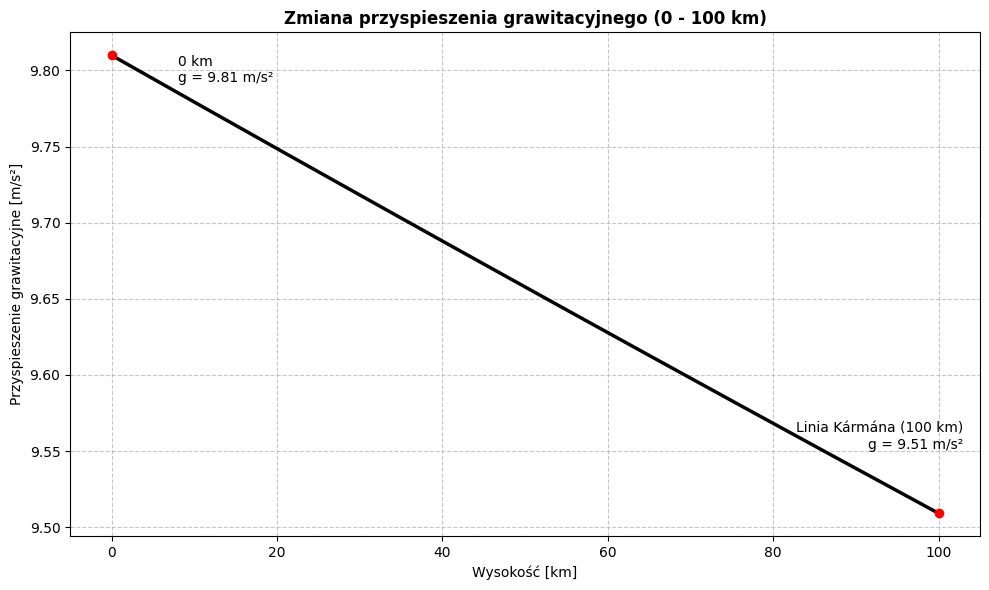

In [167]:
import numpy as np
import matplotlib.pyplot as plt

def model_gravity(h, g0=9.81, R_E=6371000):
    """
    Oblicza przyspieszenie grawitacyjne g(h) zgodnie z prawem odwrotnych kwadratów.
    """
    return g0 * (R_E / (R_E + h))**2

# Tworzymy tablicę wysokości od 0 do 100 km 
h_values = np.linspace(0, 100000, 200) 

g_values = model_gravity(h_values)

# 3. Rysowanie wykresu
plt.figure(figsize=(10, 6))
plt.plot(h_values / 1000, g_values, color="#040404", linewidth=2.5)

plt.title('Zmiana przyspieszenia grawitacyjnego (0 - 100 km)', fontweight='bold')
plt.xlabel('Wysokość [km]')
plt.ylabel('Przyspieszenie grawitacyjne [m/s²]')
plt.grid(True, linestyle='--', alpha=0.7)

# Dodanie adnotacji dla wartości skrajnych
g_start = g_values[0]
g_end = g_values[-1]

plt.scatter([0], [g_start], color='red', zorder=5)
plt.text(8, g_start, f"0 km\ng = {g_start:.2f} m/s²", va='top')

plt.scatter([100], [g_end], color='red', zorder=5)
plt.text(103, g_end +0.06, f"Linia Kármána (100 km)\ng = {g_end:.2f} m/s²", ha='right', va='top')

plt.tight_layout()
plt.show()



## 3.2. Model atmosfery (Gęstość powietrza)

Do obliczania oporu aerodynamicznego niezbędna jest znajomość gęstości powietrza na danej wysokości. W symulacji zastosowano **wykładniczy model atmosfery**, który jest uproszczeniem skomplikowanych równań hydrostatyki i termodynamiki.

###  Podstawy fizyczne
Punktem wyjścia jest wzór barometryczny wynikający z rozkładu Boltzmanna dla gazu idealnego w polu grawitacyjnym:

$$
p(h) = p_0 \cdot \exp\left( - \frac{m \cdot g \cdot h}{k_B \cdot T} \right)
$$

W symulacjach numerycznych niewygodne jest operowanie masą pojedynczej cząsteczki ($m$) czy stałą Boltzmanna ($k_B$). Dlatego parametry te grupuje się w jeden współczynnik zwany **Skalą Wysokości ($H$)**:

$$
H = \frac{k_B \cdot T}{m \cdot g} = \frac{R \cdot T}{M_{mol} \cdot g}
$$

Dla Ziemi, przyjmując średnią temperaturę $T \approx 288 \, K$ oraz masę molową powietrza $M_{mol} \approx 0,029 \, kg/mol$, skala ta wynosi około $H \approx 8500 \, m$.

###  Wzór końcowy
Po podstawieniu stałej $H$, skomplikowane równania redukują się do eleganckiej formy wykładniczej zaimplementowanej w kodzie:

$$
\rho(h) = \rho_0 \cdot \exp\left( - \frac{h}{H} \right)
$$

Gdzie $\rho_0 = 1,225 \, kg/m^3$ to standardowa gęstość na poziomie morza.


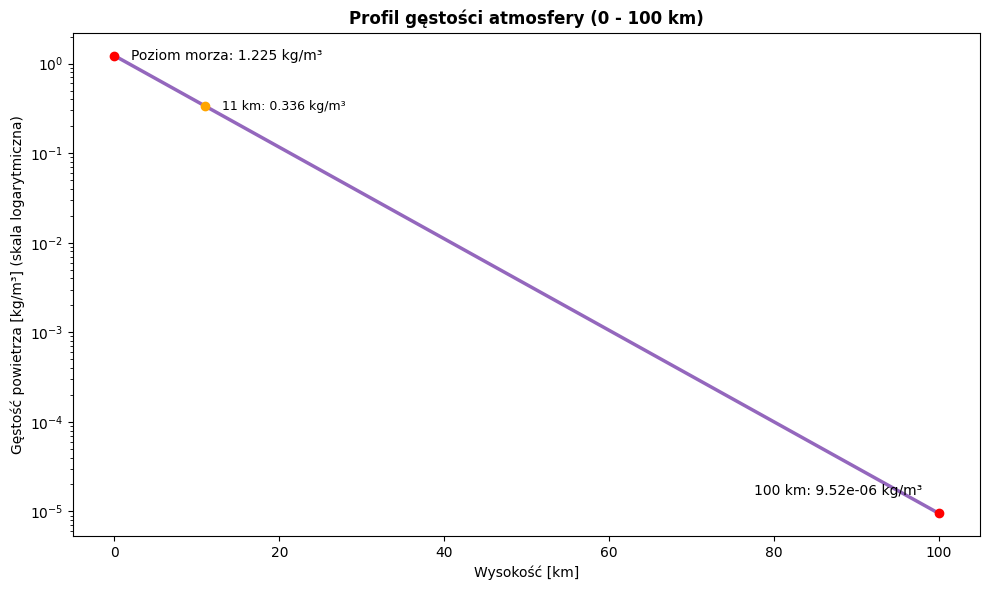

In [168]:
# 1. Definicja modelu gęstości atmosfery
def model_atmosphere(h, rho0=1.225, H_scale=8500):
    return rho0 * np.exp(-h / H_scale)

# 2. Generowanie danych (zakres 0 - 100 km)
h_values = np.linspace(0, 100000, 500)
rho_values = model_atmosphere(h_values)

# 3. Rysowanie wykresu
plt.figure(figsize=(10, 6))

# Zastosowanie skali logarytmicznej na osi Y (semilogy)
plt.semilogy(h_values / 1000, rho_values, color='#9467bd', linewidth=2.5)

plt.title('Profil gęstości atmosfery (0 - 100 km)', fontweight='bold')
plt.xlabel('Wysokość [km]')
plt.ylabel('Gęstość powietrza [kg/m³] (skala logarytmiczna)')

plt.scatter([0], [rho_values[0]], color='red', zorder=5)
plt.text(2, rho_values[0], f"Poziom morza: {rho_values[0]:.3f} kg/m³", va='center')

# Granica troposfery (h = 11 km)
h_tropo = 11000
rho_tropo = model_atmosphere(h_tropo)
plt.scatter([h_tropo/1000], [rho_tropo], color='orange', zorder=5)
plt.text(h_tropo/1000 + 2, rho_tropo, f"11 km: {rho_tropo:.3f} kg/m³", va='center', fontsize=9)

# Linia Kármána (h = 100 km)
h_karman = 100000
rho_karman = model_atmosphere(h_karman)
plt.scatter([100], [rho_karman], color='red', zorder=5)
plt.text(98, rho_karman * 1.5, f"100 km: {rho_karman:.2e} kg/m³", ha='right', va='bottom')

plt.tight_layout()
plt.show()

 Ze względu na wykładniczy charakter spadku gęstości, do wizualizacji zmian w szerokim zakresie wysokości (0–100 km) zastosowano skalę logarytmiczną na osi rzędnych (osi Y)



## 3.3. Model prędkości dźwięku (Aproksymacja liniowa)

Prędkość dźwięku jest kluczowa dla wyznaczenia liczby Macha i momentu przejścia przez barierę dźwięku (gdzie gwałtownie rośnie współczynnik oporu). W symulacji zastosowano model liniowy ograniczony do **Troposfery** ($0 - 11\,km$).

###  Linearyzacja zależności od temperatury
Dokładny wzór na prędkość dźwięku zależy od pierwiastka z temperatury ($v \propto \sqrt{T}$). Aby uzyskać prostszy model inżynierski, zastosowano rozwinięcie w szereg Taylora wokół $0^\circ C$:

1.  Wzór dokładny: $v \approx 331,3 \cdot \sqrt{1 + \frac{T_C}{273,15}}$
2.  Przybliżenie Taylora dla małych $x$: $\sqrt{1+x} \approx 1 + \frac{1}{2}x$
3.  Po podstawieniu i wymnożeniu:
    $$v \approx 331,3 + \frac{331,3}{2 \cdot 273,15} \cdot T_C \approx 331,3 + 0,6 \cdot T_C$$

Oznacza to, że prędkość dźwięku zmienia się o około **$0,6 \, m/s$ na każdy stopień Celsjusza**.

###  Wyznaczenie gradientu wysokościowego ($k$)
W standardowej atmosferze (ISA) temperatura w troposferze spada o $6,5^\circ C$ na każdy kilometr wysokości. Łącząc to z powyższą linearyzacją, otrzymujemy tempo spadku prędkości dźwięku:

$$
k = 6,5 \, \frac{^\circ C}{km} \times 0,6 \, \frac{m/s}{^\circ C} \approx 3,9 \, \frac{m/s}{km} \approx 4 \, \frac{m/s}{km}
$$

###  Implementacja numeryczna
W kodzie symulacji przyjęto liniowy spadek prędkości dźwięku o $4 \, m/s$ na każdy kilometr, startując od wartości bazowej $v_{SL} = 346 \, m/s$ (dla $25^\circ C$):

$$
v_{sound}(h) = v_{SL} - k \cdot h
$$



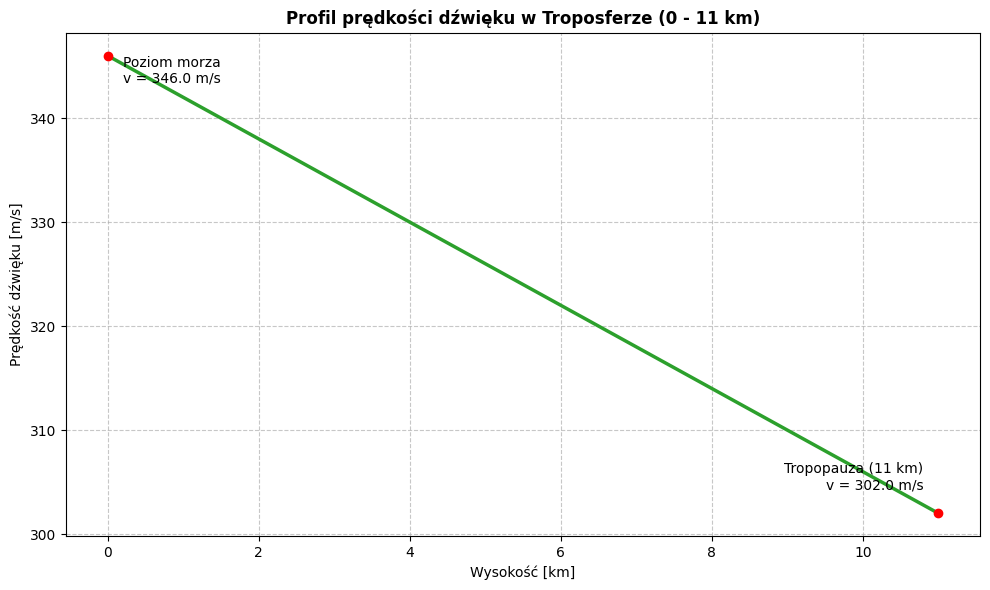

In [169]:
def model_speed_of_sound(h):
    """
    Model uproszczony: Troposfera (0-11 km).
    Startujemy od 346 m/s (dla 25 st. C).
    Spadek 4 m/s na każdy km.
    """
    
    return 346.0 - (4.0 * h / 1000.0)

h_values = np.linspace(0, 11000, 200)
v_values = model_speed_of_sound(h_values)

# 3. Rysowanie wykresu
plt.figure(figsize=(10, 6))
plt.plot(h_values / 1000, v_values, color='#2ca02c', linewidth=2.5) 

plt.title('Profil prędkości dźwięku w Troposferze (0 - 11 km)', fontweight='bold')
plt.xlabel('Wysokość [km]')
plt.ylabel('Prędkość dźwięku [m/s]')
plt.grid(True, linestyle='--', alpha=0.7)

# Adnotacje
v_start = v_values[0]
v_end = v_values[-1]

plt.scatter([0], [v_start], color='red', zorder=5)
plt.text(0.2, v_start, f"Poziom morza\nv = {v_start:.1f} m/s", va='top')

plt.scatter([11], [v_end], color='red', zorder=5)
plt.text(10.8, v_end + 2, f"Tropopauza (11 km)\nv = {v_end:.1f} m/s", ha='right', va='bottom')

plt.tight_layout()
plt.show()

 ## 3.4. Sterowany lot płaski (2D)

W symulacji mającej na celu odwzorowanie rzeczywistego lotu orbitalnego (np. do punktu MECO), nie polegamy na biernym zwrocie grawitacyjnym. Celem jest wymuszenie takiej trajektorii, która pozwoli osiągnąć zadaną prędkość i wysokość w określonym czasie. Realizuje się to poprzez **aktywny program sterowania (Pitch Program)**, czyli narzucanie kąta pochylenia rakiety w funkcji czasu.

### Układ współrzędnych i kąty sterowania

W modelu 2D kluczowe jest rozróżnienie kierunku, w którym rakieta jest zwrócona, od kierunku, w którym faktycznie się porusza. Definiujemy wektor stanu:

$$
\mathbf{y}(t) = [x, h, v, \gamma, m]
$$

Gdzie zmienne stanu to:
* **$x$** – Dystans poziomy [$m$].
* **$h$** – Wysokość [$m$].
* **$v$** – Prędkość całkowita [$m/s$].
* $\gamma$ (gamma) – Kąt toru lotu  – kierunek wektora prędkości względem lokalnego horyzontu.
* **$m$** – Masa rakiety [$kg$].

Dodatkowo wprowadzamy zmienne sterujące:
* **$\theta(t)$ (theta)** – **Kąt pochylenia rakiety** (Pitch Angle) – kierunek osi podłużnej rakiety (gdzie celują silniki). Jest to wartość narzucana przez algorytm sterowania.
* **$\alpha$ (alfa)** – **Kąt natarcia** (Angle of Attack) – różnica między osią rakiety a wektorem prędkości.

Zależność geometryczna między kątami wyraża się równaniem:
$$
\alpha = \theta - \gamma
$$

###  Równania ruchu ze sterowaniem wektorem ciągu

Gdy rakieta jest obrócona względem wektora prędkości ($\alpha \neq 0$), siła ciągu $T$ nie działa wyłącznie przyspieszająco. Rozkładamy ją na dwie składowe:
1.  **Styczną ($T \cos \alpha$):** Odpowiedzialną za zmianę prędkości $v$.
2.  **Normalną ($T \sin \alpha$):** Odpowiedzialną za zmianę kierunku lotu $\gamma$ (zakrzywianie toru).

Ostateczny układ równań różniczkowych dla sterowanego lotu przyjmuje postać:

$$
\begin{cases}
\frac{dx}{dt} = v \cos \gamma \\[8pt]
\frac{dh}{dt} = v \sin \gamma \\[8pt]
\frac{dv}{dt} = \frac{T \cos \alpha - D}{m} - g(h) \sin \gamma \\[8pt]
\frac{d\gamma}{dt} = \frac{T \sin \alpha}{m v} - \frac{1}{v} \left( g(h) - \frac{v^2}{R_Z + h} \right) \cos \gamma \\[8pt]
\frac{dm}{dt} = -\frac{T}{I_{sp} g_0}
\end{cases}
$$



## 3.4.1 Fizyczne wyprowadzenie równań ruchu

Poniżej przedstawiono uzasadnienie każdego z równań użytych w układzie, opierając się na kinematyce, dynamice Newtona oraz definicjach napędu rakietowego.

###  Kinematyka (Zmiana pozycji)

Równania te wynikają z geometrycznego rozkładu wektora prędkości w układzie współrzędnych związanych z lokalnym horyzontem.

$$
\frac{dx}{dt} = v \cos \gamma \quad , \quad \frac{dh}{dt} = v \sin \gamma
$$

**Uzasadnienie:**
Rakieta porusza się z całkowitą prędkością $v$ skierowaną pod kątem $\gamma$ względem poziomu. Aby określić zmianę położenia, rozkładamy wektor prędkości $\vec{v}$ na składowe ortogonalne:
1.  **Składowa pozioma ($v_x$):** $v_x = v \cos \gamma$. Odpowiada za przyrost dystansu ($dx$).
2.  **Składowa pionowa ($v_h$):** $v_h = v \sin \gamma$. Odpowiada za przyrost wysokości ($dh$).

Fizycznie oznacza to, że przy locie pionowym ($\gamma=90^\circ$) rakieta nie oddala się od wyrzutni, a cała prędkość zamieniana jest na wysokość. Przy locie poziomym ($\gamma=0^\circ$) wysokość pozostaje stała.

###  Dynamika wzdłużna (Zmiana prędkości)

Równanie to opisuje przyspieszenie styczne (wzdłuż toru lotu) i wynika bezpośrednio z **II Zasady Dynamiki Newtona** zrzutowanej na kierunek wektora prędkości.

$$
\frac{dv}{dt} = \frac{T \cos \alpha - D}{m} - g(h) \sin \gamma
$$

**Uzasadnienie ($F=ma$):**
Sumujemy siły działające stycznie do toru lotu:
* **$T \cos \alpha$ (Ciąg efektywny):** Jeśli rakieta leci pod kątem natarcia $\alpha$, tylko część ciągu przyspiesza ją w kierunku lotu. Czynnik $\cos \alpha$ reprezentuje tzw. *straty sterowania (Cosine Loss)*.
* **$-D$ (Opór):** Siła aerodynamiczna działa zawsze przeciwnie do wektora prędkości, hamując rakietę.
* **$-mg \sin \gamma$ (Straty grawitacyjne):** Jest to rzut siły ciężkości na oś ruchu. Podczas pionowego wznoszenia grawitacja działa z pełną siłą przeciwnie do ruchu. W locie poziomym działa prostopadle i nie hamuje bezpośrednio prędkości stycznej.

###  Model oporu aerodynamicznego ($D$)
Siła oporu $D$ (Drag) jest kluczowym czynnikiem hamującym w gęstych warstwach atmosfery. Obliczana jest za pomocą klasycznego równania aerodynamiki:

$$D = \frac{1}{2} \rho(h) v^2 C_d A$$



Gdzie:
* **$\rho(h)$** – Gęstość powietrza na wysokości $h$, wyliczana z modelu wykładniczego.
* **$v$** – Prędkość rakiety względem ośrodka [$m/s$].
* **$C_d$** – Współczynnik oporu, który w symulacji zmienia się skokowo w okolicach Mach 1, aby oddać wzrost oporu falowego.
* **$A$** – Powierzchnia czołowa rakiety [$m^2$].

### Dynamika poprzeczna (Zmiana kąta toru lotu)

Zmiana kierunku wektora prędkości wynika z działania sił prostopadłych (normalnych) do kierunku ruchu. Korzystamy z zasady dynamiki dla ruchu krzywoliniowego ($F_{\perp} = m \cdot v \cdot \dot{\gamma}$).

$$
\frac{d\gamma}{dt} = \frac{T \sin \alpha}{m v} - \frac{g(h) \cos \gamma}{v} + \frac{v \cos \gamma}{R_Z + h}
$$

**Analiza składników:**
1.  **Sterowanie silnikiem ($T \sin \alpha$):** Składowa ciągu prostopadła do osi rakiety wymusza obrót wektora prędkości. Jest to główny mechanizm sterowania.
2.  **Grawitacja ($-mg \cos \gamma$):** Składowa ciężaru działająca prostopadle do toru lotu, zakrzywiająca go w stronę Ziemi (tzw. *Gravity Turn*).
3.  **Poprawka na krzywiznę Ziemi:** Ponieważ rakieta porusza się nad kulistą planetą, horyzont "ucieka" spod niej. Generuje to pozorny ruch obrotowy układu odniesienia (siła odśrodkowa), reprezentowany przez człon $+\frac{v \cos \gamma}{R_Z + h}$.

### Bilans masy (Zużycie paliwa)

Równanie to wynika z definicji wydajności silnika rakietowego, opisanej parametrem **Impulsu Właściwego ($I_{sp}$)**.

$$
\frac{dm}{dt} = -\frac{T}{I_{sp} \cdot g_0}
$$

**Uzasadnienie:**
Impuls właściwy $I_{sp}$ określa, przez ile sekund silnik może generować 1 N ciągu, zużywając 1 N paliwa. Przekształcając wzór definicyjny $I_{sp} = T / (\dot{m} g_0)$, otrzymujemy $\dot{m} = T / (I_{sp} g_0)$. Znak minus wynika z faktu, że masa rakiety maleje w czasie pracy silników. Wzór ten wiąże bezpośrednio ciąg (sterowany przepustnicą) z tempem opróżniania zbiorników.

## 3.4.2 Legenda zmiennych i parametrów

W celu poprawnego sformułowania algorytmu numerycznego, konieczne jest zdefiniowanie wszystkich zmiennych fizycznych oraz stałych konstrukcyjnych. Poniższe tabele stanowią słownik pojęć i wartości użytych w kodzie symulacji.

### Zmienne zależne od czasu (Wektor stanu i sterowanie)

Zmienne te ulegają zmianie w każdym kroku czasowym $dt$ i definiują chwilowy stan fizyczny rakiety.

| Symbol | Nazwa zmiennej | Jednostka (SI) | Opis fizyczny |
| :---: | :--- | :---: | :--- |
| $x(t)$ | Dystans poziomy | $m$ | Odległość rakiety od miejsca startu mierzona po powierzchni Ziemi (Downrange). |
| $h(t)$ | Wysokość | $m$ | Aktualna pozycja rakiety nad poziomem morza (Altitude). |
| $v(t)$ | Prędkość całkowita | $m/s$ | Wartość wektora prędkości (Velocity Magnitude) względem środka Ziemi. |
| $\gamma(t)$ | Kąt toru lotu | $rad$ / $^\circ$ | Kierunek wektora prędkości względem lokalnego horyzontu (Flight Path Angle). |
| $\theta(t)$ | Kąt pochylenia | $rad$ / $^\circ$ | Kąt orientacji osi podłużnej rakiety względem horyzontu (Pitch Angle). |
| $\alpha(t)$ | Kąt natarcia | $rad$ / $^\circ$ | Różnica między orientacją rakiety a kierunkiem lotu ($\alpha = \theta - \gamma$). |
| $m(t)$ | Masa całkowita | $kg$ | Chwilowa masa (konstrukcja + pozostałe paliwo), malejąca w czasie pracy silników. |
| $T(t)$ | Ciąg chwilowy | $N$ | Aktualna siła ciągu, zależna od gęstości otoczenia i otwarcia przepustnicy. |
| $D(t)$ | Siła oporu | $N$ | Siła hamująca wynikająca z ciśnienia dynamicznego i kształtu rakiety ($D = 0.5 \rho v^2 C_d A$). |
| $Ma(t)$ | Liczba Macha | - | Stosunek prędkości $v$ do lokalnej prędkości dźwięku na wysokości $h$. |
| $\tau(t)$ | Przepustnica | - | Bezwymiarowy współczynnik dławienia silników (Throttle). |

###  Parametry modelu i stałe fizyczne

Wartości te są stałe dla danej konfiguracji symulacji i definiują charakterystykę Starshipa oraz środowiska ziemskiego.

| Symbol | Nazwa zmiennej | Wartość / Jednostka | Opis fizyczny |
| :---: | :--- | :---: | :--- |
| $T_{max}$ | Ciąg maksymalny | $75,9 \cdot 10^6 \, N$ | Teoretyczny maksymalny ciąg zespołu silników Raptor. |
| $I_{sp\_sl}$ | Impuls (SL) | $280 \, s$ | Wydajność silników na poziomie morza (Sea Level). |
| $I_{sp\_vac}$ | Impuls (VAC) | $327 \, s$ | Wydajność silników w próżni (Vacuum). |
| $C_{d\_base}$ | Bazowy współczynnik oporu | $0,35$ | Współczynnik oporu dla lotu poddźwiękowego. |
| $A$ | Powierzchnia czołowa | $63,62 \, m^2$ | Powierzchnia przekroju kadłuba o średnicy $9 \, m$. |
| $m_{dry}$ | Masa sucha | $kg$ | Masa konstrukcji (Booster + Payload) bez paliwa. |
| $m_{prop}$ | Masa paliwa | $kg$ | Początkowa masa materiału pędnego. |
| $g_0$ | Przyspieszenie ziemskie | $9,81 \, m/s^2$ | Przyspieszenie standardowe używane w modelach. |
| $R_Z$ | Promień Ziemi | $6\,371\,000 \, m$ | Średni promień Ziemi wykorzystywany w modelu grawitacyjnym. |
| $\rho_0$ | Gęstość SL | $1,225 \, kg/m^3$ | Standardowa gęstość powietrza przy powierzchni. |
| $H$ | Skala wysokości | $8\,500 \, m$ | Parametr spadku gęstości w modelu wykładniczym. |
| $v_{SL}$ | Prędkość dźwięku SL | $346 \, m/s$ | Prędkość dźwięku przy powierzchni Ziemi (dla $25^\circ C$). |

## 3.5 Metoda Rungego-Kutty 4. rzędu (RK4) dla układów równań

Metoda Rungego-Kutty (RK4) to jeden z najpopularniejszych algorytmów do numerycznego rozwiązywania równań różniczkowych zwyczajnych. Zapewnia doskonały balans między dokładnością a kosztem obliczeniowym.

W fizyce (np. symulacja lotu rakiety) rzadko mamy do czynienia z jednym równaniem. Zazwyczaj jest to układ równań sprzężonych. Aby rozwiązać taki układ, stosujemy metodę RK4 w wersji wektorowej.

### Sformułowanie problemu 
Mamy układ równań różniczkowych pierwszego rzędu zapisany w postaci wektorowej:

$$\frac{d\mathbf{y}}{dt} = \mathbf{f}(t, \mathbf{y})$$

Gdzie:

- $t$ – zmienna niezależna (czas).
- $\mathbf{y}$ – wektor stanu (zawiera wszystkie zmienne opisujące system, np. $[h, v, m]$).
- $\mathbf{f}$ – funkcja wektorowa zwracająca pochodne (prawe strony równań).

###  Algorytm RK4 (Krok czasowy)
Niech $h$ (lub $dt$) oznacza krok czasowy. Znamy stan układu $\mathbf{y}_n$ w chwili $t_n$. Chcemy obliczyć stan $\mathbf{y}_{n+1}$ w chwili $t_{n+1} = t_n + h$.

W metodzie RK4 obliczamy cztery pomocnicze wektory nachyleń ($\mathbf{k}$), które uśredniamy:
1. Nachylenie na początku przedziału:$$\mathbf{k}_1 = \mathbf{f}(t_n, \mathbf{y}_n)$$

2. Nachylenie w połowie (próbne A):Przewidujemy stan w połowie kroku, używając $\mathbf{k}_1$.$$\mathbf{k}_2 = \mathbf{f}\left(t_n + \frac{h}{2}, \mathbf{y}_n + \frac{h}{2}\mathbf{k}_1\right)$$

3. Nachylenie w połowie (próbne B):Korygujemy przewidywanie w połowie kroku, używając $\mathbf{k}_2$.$$\mathbf{k}_3 = \mathbf{f}\left(t_n + \frac{h}{2}, \mathbf{y}_n + \frac{h}{2}\mathbf{k}_2\right)$$

4. Nachylenie na końcu przedziału:Przewidujemy stan na końcu kroku, używając $\mathbf{k}_3$.$$\mathbf{k}_4 = \mathbf{f}(t_n + h, \mathbf{y}_n + h\mathbf{k}_3)$$

Ostateczny wzór na kolejny krok: Nowy stan to średnia ważona tych nachyleń (środkowe mają wagę 2):

$$\mathbf{y}_{n+1} = \mathbf{y}_n + \frac{h}{6} (\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4)$$

In [ ]:
def rk4_step(t, y, dt, derivatives_func):
    """
    Wykonuje jeden krok całkowania metodą Rungego-Kutty 4. rzędu.
    
    Parametry:
    t : float - Aktualny czas
    y : array - Aktualny wektor stanu [x, h, v, gamma, m]
    dt : float - Krok czasowy
    derivatives_func : function - Funkcja zwracająca pochodne dy/dt = f(t, y)
    
    Zwraca:
    y_next : array - Wektor stanu w kolejnym kroku czasowym (t + dt)
    """
    # k1: Pochodna na początku przedziału
    k1 = derivatives_func(t, y)
    
    # k2: Pochodna w połowie przedziału 
    k2 = derivatives_func(t + dt/2.0, y + (dt/2.0) * k1)
    
    # k3: Druga pochodna w połowie przedziału 
    k3 = derivatives_func(t + dt/2.0, y + (dt/2.0) * k2)
    
    # k4: Pochodna na końcu przedziału 
    k4 = derivatives_func(t + dt, y + dt * k3)
    
    # Średnia ważona nachyleń
    y_next = y + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    
    return y_next

# 4. Implementacja modelu numerycznego i środowisko symulacyjne

Po zdefiniowaniu teoretycznych podstaw dynamiki lotu rakiety oraz matematycznego opisu sił działających na obiekt w atmosferze, kolejnym etapem pracy jest ich praktyczna implementacja w formie kodu. Rozdział czwarty poświęcono szczegółowemu omówieniu architektury opracowanego symulatora, który został stworzony w środowisku języka **Python** z wykorzystaniem bibliotek obliczeniowych *NumPy* oraz *SciPy*.

W niniejszym rozdziale przedstawiono strukturę logiczną programu, w tym:
1.  **Algorytm solera:** Zastosowanie metody całkowania numerycznego Rungego-Kutty 4. rzędu (RK4) do rozwiązywania układu równań różniczkowych ruchu.

2.  **Parametryzację modelu:** Dobór kluczowych danych wejściowych, takich jak charakterystyka ciągu silników Raptor, zmienna masa startowa, profile aerodynamiczne ($C_d$) oraz model atmosfery wzorcowej.

3.  **Logikę sterowania (Guidance Logic):** Metodologię odtworzenia profilu pochylenia rakiety (*pitch schedule*) na podstawie analizy materiałów wideo z misji IFT-5, co pozwoliło na zasymulowanie manewru *Gravity Turn*.

Celem tej części pracy jest zaprezentowanie narzędzia badawczego, którego wyniki zostaną poddane walidacji w kolejnym rozdziale.

In [170]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d

def create_linear_guidance():
    """
    Tworzy profil sterowania na podstawie punktów kluczowych ze zdjęć.
    Zwraca funkcję interpolującą odchylenie od pionu (deviation).
    """
    # Punkty czasowe (sekundy od startu symulacji)
    times = [0, 10, 56, 159, 165]
    
    # Kąty Pitch (względem horyzontu):
    # 0-10s: 90 stopni (pion)
    # 56s:   77 stopni (ze zdjęcia 1)
    # 159s:  32 stopnie (ze zdjęcia 2)
    target_pitch = [90, 88, 77, 32, 30] 
    
    deviation_values = [90 - p for p in target_pitch]

    return interp1d(times, deviation_values, kind='linear', fill_value="extrapolate")

def run_starship_simulation(guidance_func, 
                            t_max=165, 
                            dt=0.05, 
                            m_payload=1330000,
                            m_booster_dry=230000,
                            m_booster_prop=3400000,
                            thrust_limit=0.98,
                            Cd_base=0.35,
                            enable_throttling=True,
                            enable_mass_change=True):
    
    g0 = 9.81
    R_E = 6371000
    rho0 = 1.225
    A_ref = np.pi * (4.5**2)
    thrust_max_theoretical = 75.9e6 
    isp_sea_level = 280.0
    isp_vacuum = 327.0
    
    m_start = m_payload + m_booster_dry + m_booster_prop
    m_dry = m_payload + m_booster_dry
    HOLD_DOWN_TIME = 2.0 

    def calculate_throttle(t):
        if not enable_throttling:
            return 1.0 if t > 2.0 else t / 2.0
        if t < 2.0: return t / 2.0
        elif t < 50.0: return 0.9
        elif 50.0 <= t < 75.0: return 0.75
        elif 75.0 <= t < 130.0: return 0.80
        else: return 0.50

    def compute_derivatives(t, state):
        x, h, v, gamma, m = state
        
        # Modele środowiskowe
        vsound = model_speed_of_sound(h)
        mach = v / vsound
        rho = model_atmosphere(h)
        g_h = model_gravity(h)
        
        # Aerodynamika
        if 0.85 < mach < 1.15: Cd = 0.60
        else: Cd = Cd_base
        D = 0.5 * rho * (v**2) * Cd * A_ref

        # Napęd
        if m < m_dry:
            current_thrust = 0.0; dm_dt = 0.0
        else:
            throttle = calculate_throttle(t)
            if t < HOLD_DOWN_TIME: throttle = 0.0
            
            current_thrust = thrust_max_theoretical * thrust_limit * throttle
            pressure_factor = rho / rho0
            current_isp = isp_vacuum - (isp_vacuum - isp_sea_level) * pressure_factor
            
            if enable_mass_change:
                dm_dt = -current_thrust / (current_isp * g0)
            else:
                dm_dt = 0.0

        # Sterowanie
        pitch_deviation = guidance_func(t)
        theta_target = np.deg2rad(90.0 - pitch_deviation)
        alpha = theta_target - gamma
        
        # Dynamika
        if m >= m_dry and current_thrust > 0:
            thrust_accel = (current_thrust * np.cos(alpha)) / m
            drag_accel = D / m
            gravity_drag = g_h * np.sin(gamma)
            dv_dt = thrust_accel - drag_accel - gravity_drag
            
            if v > 10.0:
                centrifugal = (v**2) / (R_E + h)
                turning_force = (current_thrust * np.sin(alpha)) / (m * v)
                gravity_turn = (g_h - centrifugal) * np.cos(gamma) / v
                dgamma_dt = turning_force - gravity_turn
            else: dgamma_dt = 0.0
        else:
            # Lot bez napędu
            dv_dt = -(D/m) - g_h*np.sin(gamma)
            if v > 1.0: 
                dgamma_dt = - (g_h - (v**2)/(R_E + h)) * np.cos(gamma) / v
            else: dgamma_dt = 0

        dx_dt = v * np.cos(gamma)
        dh_dt = v * np.sin(gamma)
        
        if t < HOLD_DOWN_TIME: return np.array([0.0, 0.0, 0.0, 0.0, 0.0])
        return np.array([dx_dt, dh_dt, dv_dt, dgamma_dt, dm_dt])

    # Pętla głowna
    num_steps = int(t_max / dt)
    t_arr = np.linspace(0, t_max, num_steps + 1)
    results = np.zeros((num_steps + 1, 5)) 
    results[0] = [0, 0, 0, np.pi/2, m_start]
    
    # Inicjalizacja tablic logów
    log_thrust = np.zeros(num_steps + 1)
    log_drag = np.zeros(num_steps + 1)
    log_rho = np.zeros(num_steps + 1)
    log_mach = np.zeros(num_steps + 1)
    log_pitch = np.zeros(num_steps + 1)
    log_alpha = np.zeros(num_steps + 1)
    log_throttle = np.zeros(num_steps + 1)

    for i in range(num_steps):
        t_curr = t_arr[i]
        y_curr = results[i]
        
        # KROK CAŁKOWANIA
        results[i+1] = rk4_step(t_curr, y_curr, dt, compute_derivatives)
        
        # jeszcze raz aby zapisac dane 
        x, h, v, gamma, m = y_curr
        
        vsound = model_speed_of_sound(h)
        mach = v / vsound
        rho = model_atmosphere(h)
        
        # Sterowanie
        pitch_deviation = guidance_func(t_curr)
        theta_target = np.deg2rad(90.0 - pitch_deviation)
        alpha = theta_target - gamma
        
        # Aerodynamika
        if 0.85 < mach < 1.15: Cd_log = 0.60
        else: Cd_log = Cd_base
        # Opór liczony zawsze
        D = 0.5 * rho * (v**2) * Cd_log * A_ref
        
        # Napęd
        throttle = calculate_throttle(t_curr)
        if m < m_dry or t_curr < HOLD_DOWN_TIME:
            current_thrust = 0.0
            throttle = 0.0
        else:
            current_thrust = thrust_max_theoretical * thrust_limit * throttle

        # Zapis do tablic
        log_thrust[i] = current_thrust
        log_drag[i] = D
        log_rho[i] = rho
        log_mach[i] = mach
        log_pitch[i] = np.degrees(theta_target)
        log_alpha[i] = np.degrees(alpha)
        log_throttle[i] = throttle

    # Wyrównanie ostatnich elementów
    for arr in [log_thrust, log_drag, log_rho, log_mach, log_pitch, log_alpha, log_throttle]: 
        arr[-1] = arr[-2]

    return {
        't': t_arr, 'x': results[:, 0], 'h': results[:, 1], 'v': results[:, 2], 
        'gamma': np.degrees(results[:, 3]), 'm': results[:, 4],
        'thrust': log_thrust, 'drag': log_drag, 'rho': log_rho, 'mach': log_mach,
        'pitch': log_pitch, 'alpha': log_alpha, 'throttle': log_throttle,
        'meta': {'m_start': m_start, 'm_dry': m_dry}
    }
guidance = create_linear_guidance()
results = run_starship_simulation(guidance)

## 5. Metryki inżynierskie i analiza wynikow

W celu oceny poprawności lotu oraz obciążeń działających na konstrukcję rakiety, w module analizy wyliczane są trzy kluczowe metryki.

###  Ciśnienie dynamiczne ($q$)
Ciśnienie dynamiczne określa obciążenie aerodynamiczne działające na powierzchnię rakiety. Jest ono funkcją gęstości atmosfery oraz kwadratu prędkości:

$$q = \frac{1}{2} \cdot \rho \cdot v^2$$

W kodzie wynik konwertowany jest na kilopaskale [kPa] dla lepszej czytelności wykresów:
`q_kpa = 0.5 * rho * (v**2) / 1000.0`

###  Przeciążenie ($G\text{-}Force$)
Wskaźnik ten określa przyspieszenie odczuwalne wzdłuż osi podłużnej rakiety, wyrażone w jednostkach przyspieszenia ziemskiego ($g$). Obliczane jest z wypadkowej siły ciągu i oporu podzielonej przez aktualną masę:

$$a_{G} = \frac{T - D}{m \cdot 9,81}$$

Gdzie:
* $T$ – Ciąg silników.
* $D$ – Siła oporu aerodynamicznego.
* $m$ – Aktualna masa rakiety.

### . Stosunek ciągu do ciężaru ($TWR$)
Wskaźnik $TWR$ (Thrust-to-Weight Ratio) informuje o zdolności rakiety do pokonania przyciągania grawitacyjnego. W modelu uwzględniono zmienność lokalnego przyspieszenia ziemskiego $g(h)$ wraz z wysokością:

$$TWR = \frac{T}{m \cdot g(h)}$$

Wartość $g(h)$ wyliczana jest zgodnie z wcześniej zdefiniowanym prawem odwrotnych kwadratów:
$$g(h) = 9,81 \cdot \left( \frac{R_Z}{R_Z + h} \right)^2$$

In [155]:
def calculate_engineering_metrics(data):
    t, v, m, rho, thrust, drag, h = data['t'], data['v'], data['m'], data['rho'], data['thrust'], data['drag'], data['h']
    
    # Dynamic Pressure
    q_kpa = 0.5 * rho * (v**2) / 1000.0
    
    # G-Force
    mask = m > 0
    g_force = np.zeros_like(t)
    g_force[mask] = (thrust[mask] - drag[mask]) / m[mask] / 9.81
    
    # TWR
    g_local = 9.81 * (6371000 / (6371000 + h))**2
    twr = np.zeros_like(t)
    twr[mask] = thrust[mask] / (m[mask] * g_local[mask])
    
    return q_kpa, g_force, twr


## 5.2 Profil lotu

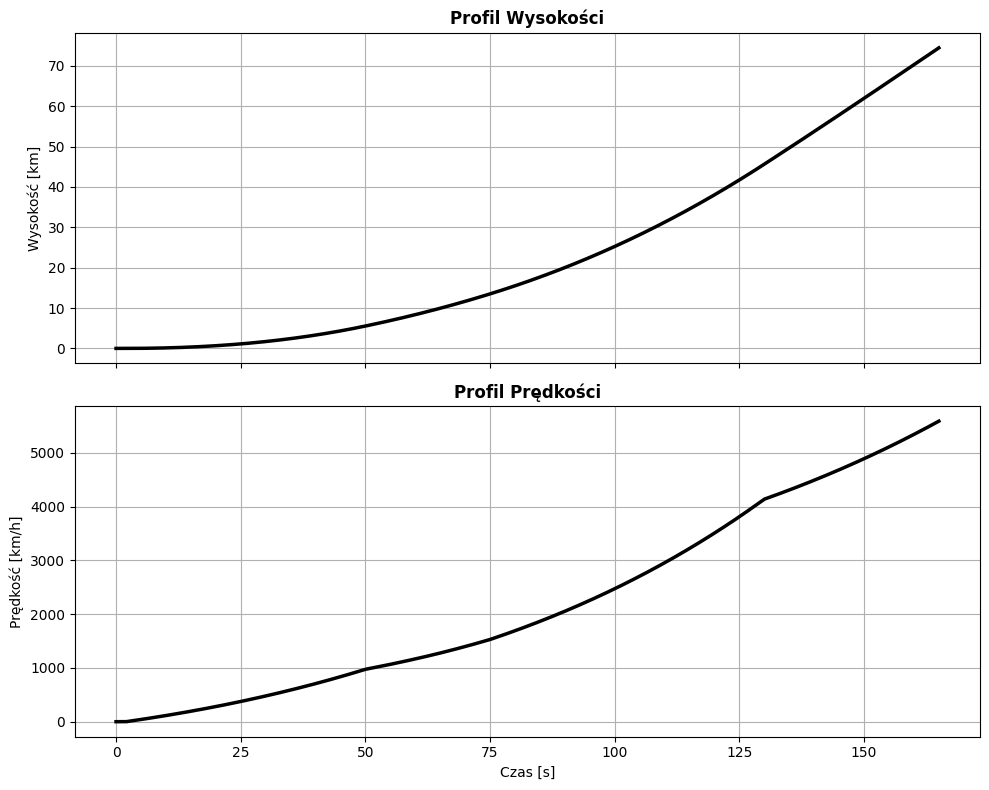

In [156]:
def plot_flight_profile(data):
    t = data['t']
    h_km = data['h'] / 1000
    v_kmh = data['v'] * 3.6
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    ax1.plot(t, h_km, color="#000000", linewidth=2.5)
    ax1.set_title('Profil Wysokości', fontweight='bold')
    ax1.set_ylabel('Wysokość [km]')
    ax1.grid(True)
    
    ax2.plot(t, v_kmh, color="#000000", linewidth=2.5)
    ax2.set_title('Profil Prędkości', fontweight='bold')
    ax2.set_ylabel('Prędkość [km/h]')
    ax2.set_xlabel('Czas [s]')
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()
plot_flight_profile(results)

Pierwszy wykres przedstawia przyrost wysokości rakiety nad poziomem morza ($h$).
* **Skala**: Wartości są konwertowane z metrów na kilometry ($h / 1000$) dla zwiększenia czytelności.
* **Zastosowanie**: Pozwala na ocenę pionowego postępu misji oraz identyfikację fazy lotu.

Drugi wykres obrazuje przyrost prędkości całkowitej ($v$) w czasie.
* **Skala**: Prędkość jest przeliczana na kilometry na godzinę ($v \cdot 3,6$).
* **Zastosowanie**: Umożliwia weryfikację momentu osiągnięcia prędkości dźwięku (faza transoniczna) oraz końcowej prędkości w momencie MECO.

## 5.3 Analiza kątów

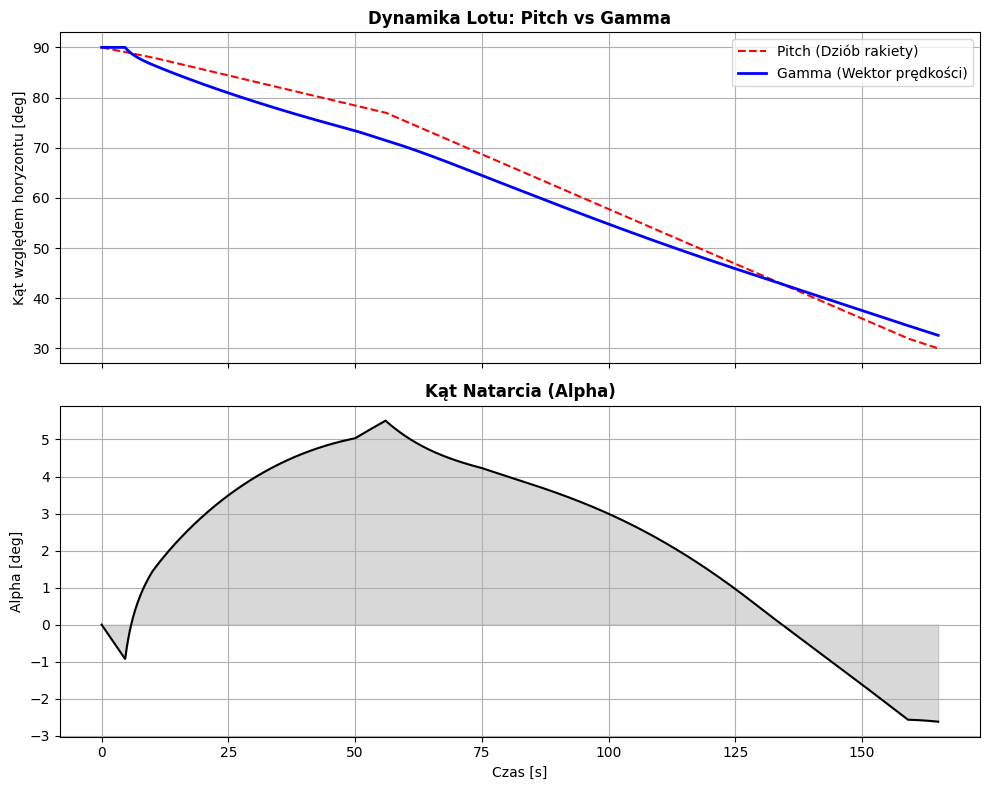

In [171]:
def plot_angles_analysis(data):
    """Nowy wykres: Porównanie Pitch (gdzie celujemy) vs Gamma (gdzie lecimy)"""
    t = data['t']
    pitch = data['pitch'] 
    gamma = data['gamma'] 
    alpha = data['alpha'] 
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    # Wykres 1: Trajektoria vs Celowanie
    ax1.plot(t, pitch, 'r--', label='Pitch (Dziób rakiety)', linewidth=1.5)
    ax1.plot(t, gamma, 'b-', label='Gamma (Wektor prędkości)', linewidth=2.0)
    ax1.set_title('Dynamika Lotu: Pitch vs Gamma', fontweight='bold')
    ax1.set_ylabel('Kąt względem horyzontu [deg]')
    ax1.legend()
    ax1.grid(True)
    
    # Wykres 2: Kąt Natarcia
    ax2.plot(t, alpha, 'k', linewidth=1.5)
    ax2.fill_between(t, alpha, 0, color='gray', alpha=0.3)
    ax2.set_title('Kąt Natarcia (Alpha)', fontweight='bold')
    ax2.set_ylabel('Alpha [deg]')
    ax2.set_xlabel('Czas [s]')
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()
plot_angles_analysis(results)

Dynamika kątowa i orientacja (Pitch vs Gamma):
Wykres zestawia kąt pochylenia kadłuba ($\theta$ - Pitch) z faktycznym kierunkiem wektora prędkości ($\gamma$ - Gamma)

Kąt Natarcia ($\alpha$): Przedstawiony jako różnica $\alpha = \theta - \gamma$. Monitorowanie $\alpha$ jest niezbędne, gdyż zbyt duże odchylenie przy wysokim ciśnieniu dynamicznym mogłoby doprowadzić do utraty kontroli nad pojazdem lub jego zniszczenia


## 5.4 Status paliwa

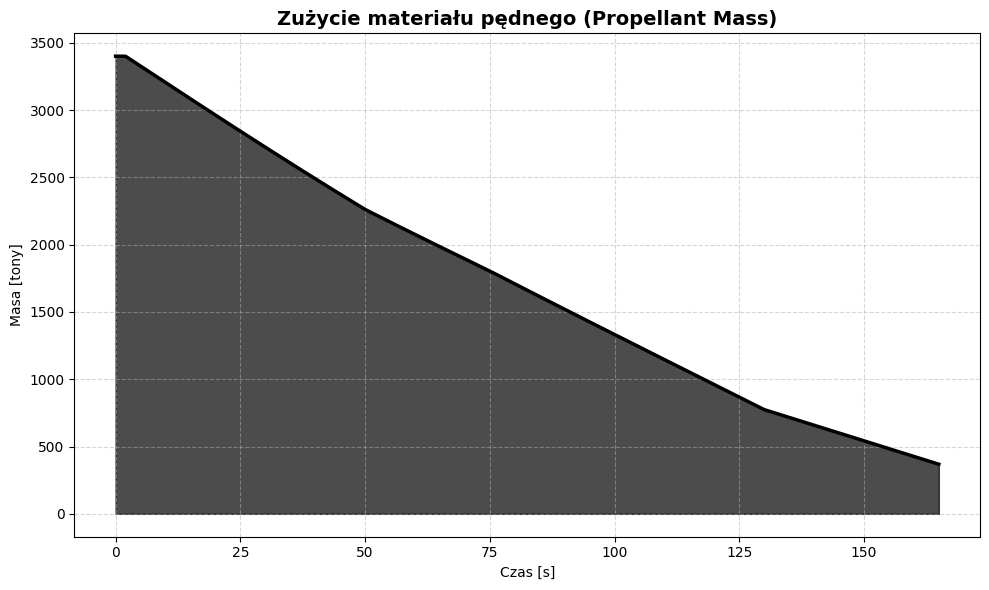

In [172]:
def plot_fuel_status(data):
    """Wykres 4: Paliwo (Całkowita masa materiału pędnego)"""
    t = data['t']
    prop_mass_tonnes = np.maximum(data['m'] - data['meta']['m_dry'], 0) / 1000.0
    
    plt.figure(figsize=(10, 6))
    
    # Wykres obszarowy dla całkowitej masy paliwa
    plt.fill_between(t, prop_mass_tonnes, color="#000000", alpha=0.7, label='Suma paliwa i utleniacza')
    plt.plot(t, prop_mass_tonnes, color="#000000", linewidth=2.5)
    
    plt.title('Zużycie materiału pędnego (Propellant Mass)', fontsize=14, fontweight='bold')
    plt.xlabel('Czas [s]')
    plt.ylabel('Masa [tony]')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_fuel_status(results)

Zmiany nachylenia krzywej (lub jej załamania) odpowiadają procedurom dławienia silników (throttling) w celu ograniczenia przeciążeń lub ciśnienia dynamicznego.

# 5.5 Trajektoria lotu

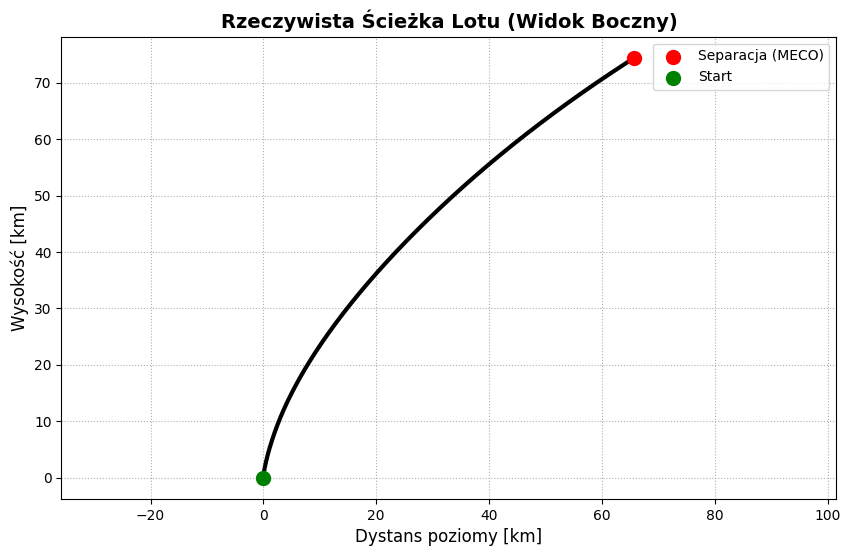

In [159]:
def plot_trajectory(data):
    """Wykres 2: Trajektoria 2D z wypełnieniem"""
    x_km = data['x'] / 1000
    h_km = data['h'] / 1000
    
    plt.figure(figsize=(10, 6))
    plt.plot(x_km, h_km, color="#000000", linewidth=3)
    plt.title('Rzeczywista Ścieżka Lotu (Widok Boczny)', fontsize=14, fontweight='bold')
    plt.xlabel('Dystans poziomy [km]', fontsize=12)
    plt.ylabel('Wysokość [km]', fontsize=12)
    plt.axis('equal') 
    plt.grid(True, linestyle=':')
    plt.scatter(x_km[-1], h_km[-1], color='red', s=100, label='Separacja (MECO)', zorder=5)
    plt.scatter(0, 0, color='green', s=100, label='Start', zorder=5)
    plt.legend()
    plt.show()
plot_trajectory(results)

## 5.6 Panel

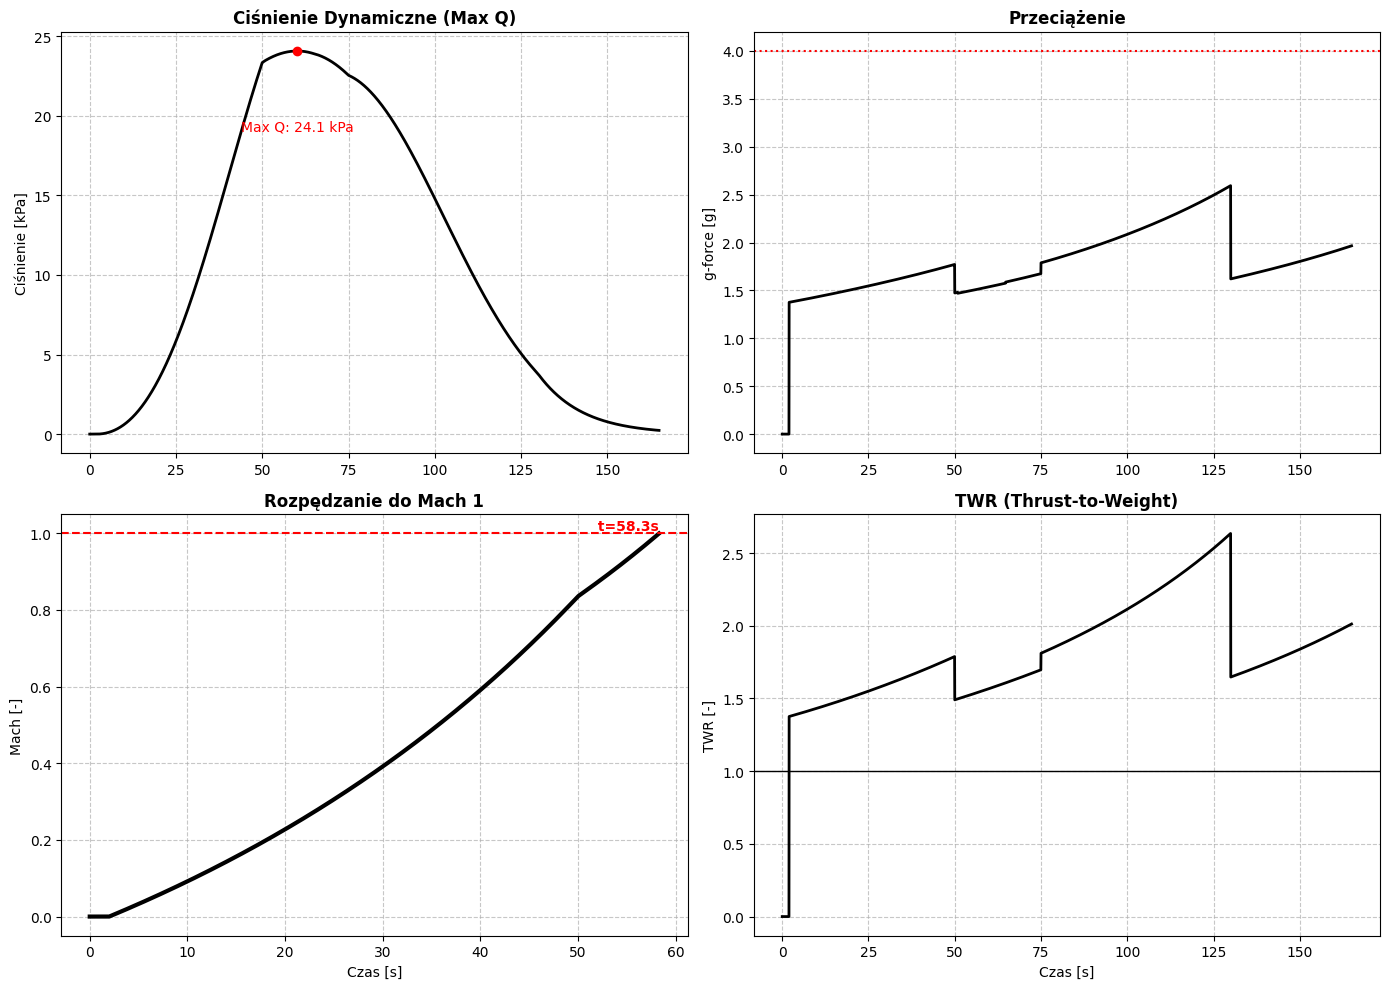

In [173]:
def plot_engineering_panel(data):
    """
    Rysuje panel 4 wykresów inżynierskich.
    Wykres Macha został zmodyfikowany tak, aby kończył się po osiągnięciu Mach 1.
    """
    # 1. Obliczenia pomocnicze (lokalne)
    t, v, m, rho, thrust, drag, h = data['t'], data['v'], data['m'], data['rho'], data['thrust'], data['drag'], data['h']
    mach = data['mach']
    
    # Ciśnienie dynamiczne [kPa]
    q_kpa = 0.5 * rho * (v**2) / 1000.0
    
    # Przeciążenie [g]
    mask = m > 0
    g_force = np.zeros_like(t)
    g_force[mask] = (thrust[mask] - drag[mask]) / m[mask] / 9.81
    
    # TWR
    g_local = 9.81 * (6371000 / (6371000 + h))**2
    twr = np.zeros_like(t)
    twr[mask] = thrust[mask] / (m[mask] * g_local[mask])

    # 2. Rysowanie
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    
    # A. Max Q
    axs[0,0].plot(t, q_kpa, color='black', linewidth=2)
    axs[0,0].set_title('Ciśnienie Dynamiczne (Max Q)', fontweight='bold')
    axs[0,0].set_ylabel('Ciśnienie [kPa]')
    axs[0,0].grid(True, linestyle='--', alpha=0.7)
    
    max_q_idx = np.argmax(q_kpa)
    axs[0,0].scatter(t[max_q_idx], q_kpa[max_q_idx], color='red', zorder=5)
    axs[0,0].text(t[max_q_idx], q_kpa[max_q_idx]-5, f"Max Q: {q_kpa[max_q_idx]:.1f} kPa", ha='center', color='red')

    # B. G-Force
    axs[0,1].plot(t, g_force, color='black', linewidth=2)
    axs[0,1].set_title('Przeciążenie', fontweight='bold')
    axs[0,1].set_ylabel('g-force [g]')
    axs[0,1].grid(True, linestyle='--', alpha=0.7)
    axs[0,1].axhline(4.0, color='red', linestyle=':', label='Limit 4g')

    idx_limit = np.argmax(mach >= 1.0)
    
    t_crop = t[:idx_limit]
    mach_crop = mach[:idx_limit]
    
    axs[1,0].plot(t_crop, mach_crop, color='black', linewidth=3)
    axs[1,0].set_title(f'Rozpędzanie do Mach 1', fontweight='bold')
    axs[1,0].set_ylabel('Mach [-]')
    axs[1,0].set_xlabel('Czas [s]')
    axs[1,0].grid(True, linestyle='--', alpha=0.7)
    
    # Oznaczenie granicy
    axs[1,0].axhline(1.0, color='red', linestyle='--')
    if len(t_crop) > 0:
        axs[1,0].text(t_crop[-1], 1.0, f" t={t_crop[-1]:.1f}s", ha='right', va='bottom', color='red', fontweight='bold')

    # D. TWR
    axs[1,1].plot(t, twr, color="black", linewidth=2)
    axs[1,1].set_title('TWR (Thrust-to-Weight)', fontweight='bold')
    axs[1,1].set_ylabel('TWR [-]')
    axs[1,1].set_xlabel('Czas [s]')
    axs[1,1].grid(True, linestyle='--', alpha=0.7)
    axs[1,1].axhline(1.0, color='black', linewidth=1)

    plt.tight_layout()
    plt.show()
plot_engineering_panel(results)

## 5.7 Moc silników

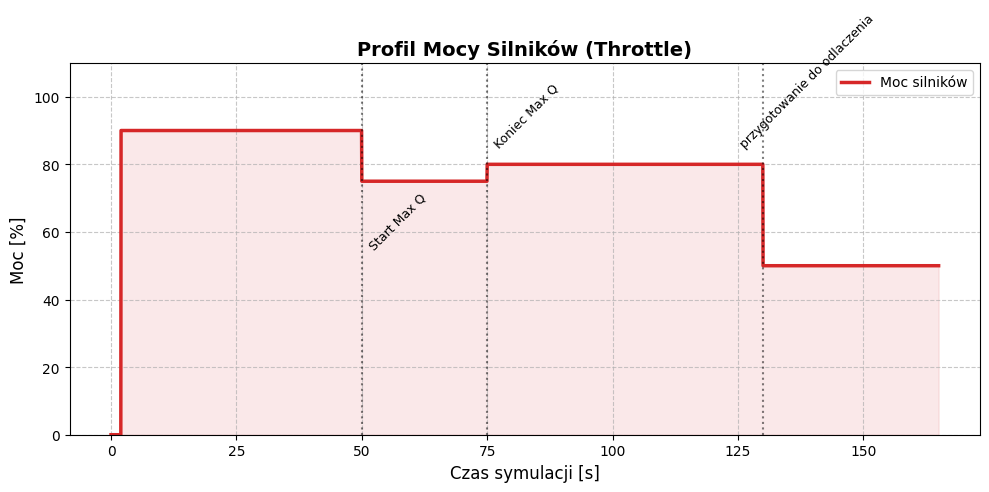

In [174]:
def plot_throttle_profile(data):
    """
    Rysuje wykres sterowania mocą silników (Throttle) w czasie.
    """
    t = data['t']
    # Zamieniamy 0.0-1.0 na procenty 0-100%
    throttle_pct = data['throttle'] * 100.0
    
    plt.figure(figsize=(10, 5))
    
    plt.plot(t, throttle_pct, color='#d62728', linewidth=2.5, label='Moc silników')
    
    plt.fill_between(t, throttle_pct, color='#d62728', alpha=0.1)
    
    plt.title('Profil Mocy Silników (Throttle)', fontsize=14, fontweight='bold')
    plt.ylabel('Moc [%]', fontsize=12)
    plt.xlabel('Czas symulacji [s]', fontsize=12)
    
    plt.ylim(0, 110)
    plt.grid(True, linestyle='--', alpha=0.7)
    
    plt.axvline(50, color='black', linestyle=':', alpha=0.5)
    plt.text(51, 55, "Start Max Q ", fontsize=9, rotation=45)
    
    plt.axvline(75, color='black', linestyle=':', alpha=0.5)
    plt.text(76, 85, "Koniec Max Q ", fontsize=9, rotation=45)

    plt.axvline(130, color='black', linestyle=':', alpha=0.5)
    plt.text(125, 85, "przygotowanie do odlaczenia ", fontsize=9, rotation=45)

    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()
plot_throttle_profile(results)

## 6. Porównanie wyników symulacji z danymi rzeczywistymi (IFT-5)

Kluczowym elementem weryfikacji poprawności modelu fizycznego jest konfrontacja uzyskanych wyników z danymi empirycznymi. W przypadku testów systemów nośnych firmy SpaceX, takich jak **Starship (misja IFT-5)**, proces ten napotyka na wyzwania natury informacyjnej.

### Metodologia pozyskiwania danych
Ze względu na brak publicznie dostępnych, oficjalnych plików CSV czy logów nawigacyjnych, walidacja opiera się na metodzie **analizy telemetryki wizualnej**. Proces ten obejmuje:

* **Ekstrakcję danych ze streamu:** Wykorzystanie klatek kluczowych z oficjalnej transmisji na żywo jako punktów kontrolnych dla czasu ($T+$), wysokości oraz prędkości.
* **Analizę geometryczną nachylenia:** Samodzielne wyznaczenie kąta pochylenia rakiety (*pitch*) przy użyciu narzędzi pomiarowych na zrzutach ekranu.
* **Aproksymację profilu sterowania:** Wykorzystanie powyższych punktów do stworzenia funkcji `create_linear_guidance`, która zastępuje brakujące oficjalne dane sterowania (*guidance logs*).

### Ograniczenia badawcze
Należy zaznaczyć, że dane odczytane z telemetryki wizualnej są obarczone błędem wynikającym z:
1.  **Perspektywy kamery**, która może wprowadzać niewielkie przekłamania w wizualnym odbiorze kąta nachylenia.
2.  **Częstotliwości odświeżania** nakładki graficznej na transmisji, która nie zawsze jest idealnie zsynchronizowana z czasem rzeczywistym procesora lotu.

Mimo tych ograniczeń, zestawienie to pozwala na rzetelną ocenę, czy opracowany model numeryczny poprawnie oddaje charakterystykę lotu w gęstych warstwach atmosfery oraz w fazie dynamicznego zwiększania prędkości.

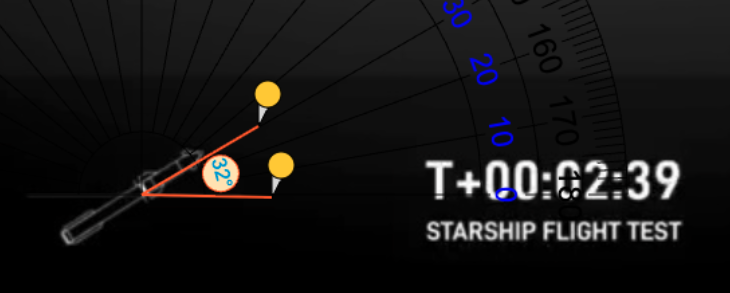
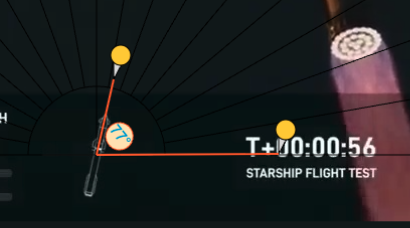

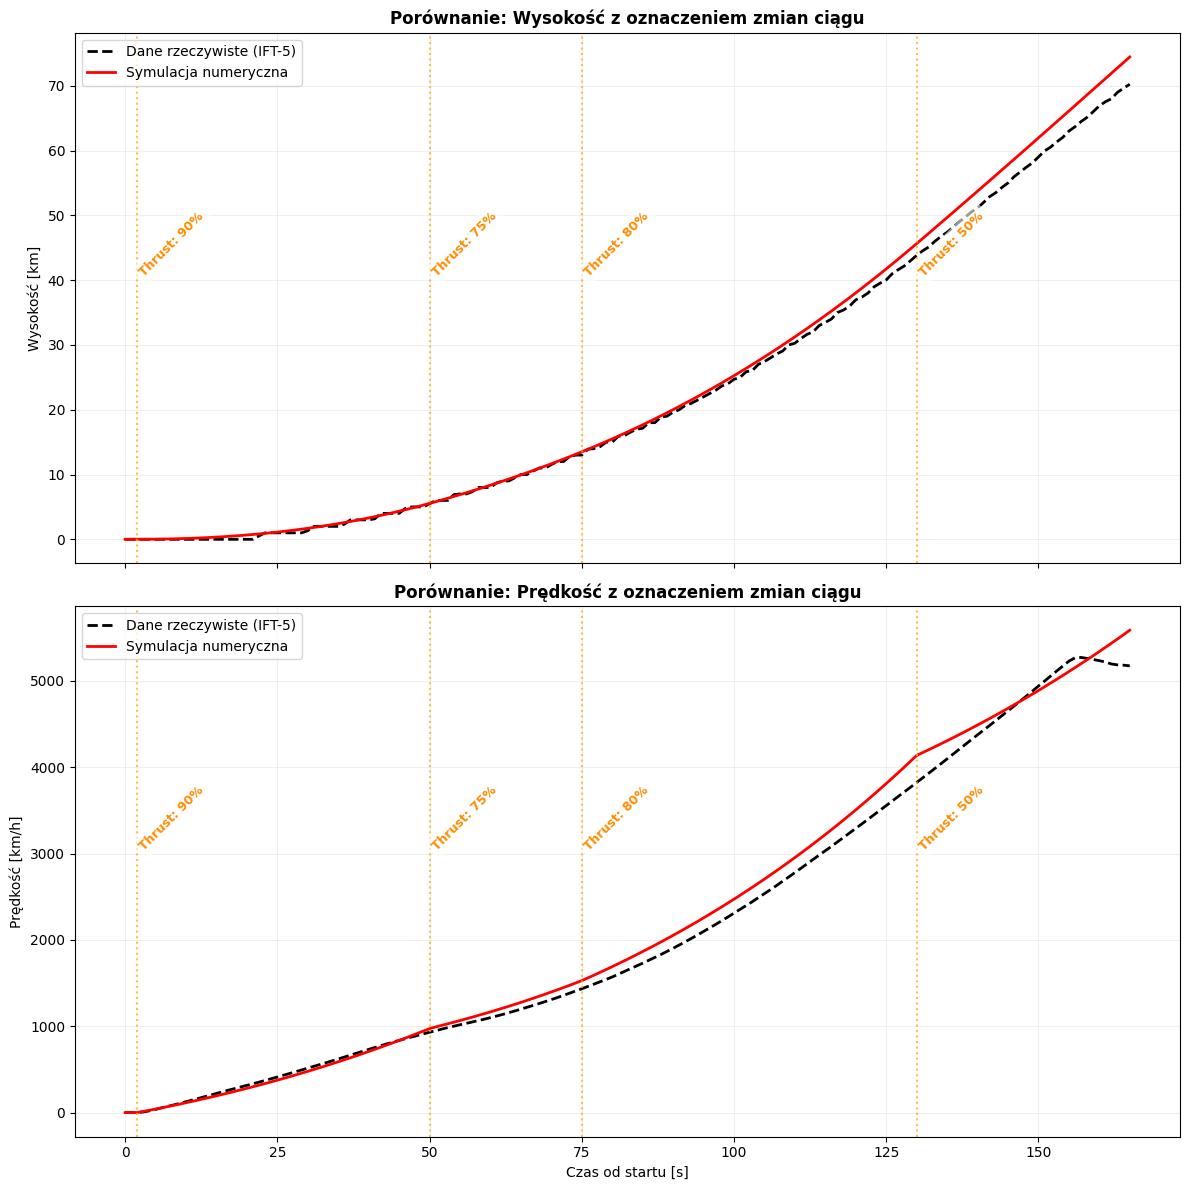

In [176]:
# 1. Wczytanie danych 
df = pd.read_csv('IFT-5 Telemetry.csv')
df.columns = df.columns.str.strip()
df['Seconds'] = (df['MissionTime'] * 86400).astype(int)

booster_cols = ['BoosterAltitude_Corrected', 'BoosterVelocity_Corrected']
for col in booster_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')

df_booster = df[df['Seconds'] <= 165]
df_result = df_booster.groupby('Seconds')[booster_cols].mean().reset_index()

def plot_comparison_with_thrust(df_real, results_sim):
    """
    Nakłada dane rzeczywiste na symulację oraz zaznacza punkty zmiany ciągu silników.
    """
    t_sim = results_sim['t']
    h_sim_km = results_sim['h'] / 1000.0
    v_sim_kmh = results_sim['v'] * 3.6
    throttle = results_sim['throttle']

    # Wykrywanie zmian ciągu (gdzie throttle[i] != throttle[i-1])
    change_indices = np.where(np.diff(throttle) != 0)[0] + 1
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12), sharex=True)

    # Funkcja pomocnicza do rysowania znaczników ciągu
    def add_thrust_markers(ax):
        for idx in change_indices:
            t_event = t_sim[idx]
            thr_val = throttle[idx] * 100
            
            ax.axvline(x=t_event, color='orange', linestyle=':', alpha=0.7, linewidth=1.5)

            y_min, y_max = ax.get_ylim()
            ax.text(t_event, y_max * 0.65, f'Thrust: {thr_val:.0f}%', 
                    color='darkorange', rotation=45, verticalalignment='top', 
                    fontweight='bold', fontsize=9, bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
    # wykres 1
    ax1.plot(df_real['Seconds'], df_real['BoosterAltitude_Corrected'], 
             label='Dane rzeczywiste (IFT-5)', color='black', linestyle='--', linewidth=2)
    ax1.plot(t_sim, h_sim_km, 
             label='Symulacja numeryczna', color='red', linewidth=2)
    
    ax1.set_ylabel('Wysokość [km]')
    ax1.set_title('Porównanie: Wysokość z oznaczeniem zmian ciągu', fontweight='bold')
    add_thrust_markers(ax1)
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.2)
    # wykres 2
    ax2.plot(df_real['Seconds'], df_real['BoosterVelocity_Corrected'], 
             label='Dane rzeczywiste (IFT-5)', color='black', linestyle='--', linewidth=2)
    ax2.plot(t_sim, v_sim_kmh, 
             label='Symulacja numeryczna', color='red', linewidth=2)
    
    ax2.set_ylabel('Prędkość [km/h]')
    ax2.set_xlabel('Czas od startu [s]')
    ax2.set_title('Porównanie: Prędkość z oznaczeniem zmian ciągu', fontweight='bold')
    add_thrust_markers(ax2)
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.2)

    plt.tight_layout()
    plt.show()

plot_comparison_with_thrust(df_result, results)

## Podsumowanie walidacji modelu

Opracowany model numeryczny wykazuje wysoką zbieżność z danymi rzeczywistymi misji IFT-5, poprawnie odwzorowując charakterystykę lotu Boostera w badanych przedziałach czasowych. Zaimplementowany algorytm całkowania RK4 oraz profil sterowania oparty na punktach kluczowych pozwoliły na zachowanie odpowiedniej dynamiki lotu, co jest szczególnie widoczne w spójności trendów przyrostu prędkości i wysokości.

Odnotowane rozbieżności między symulacją a telemetryką wynikają z koniecznych uproszczeń oraz ograniczeń w dostępie do danych:
* **Uproszczona aerodynamika:** Przyjęcie skokowych wartości współczynnika $C_d$ (0.35 lub 0.60) nie oddaje w pełni płynnych zmian oporu wynikających ze zmiennego kąta natarcia oraz liczby Macha.
* **Brak oficjalnych logów:** Ze względu na brak bezpośredniego dostępu do danych nawigacyjnych SpaceX, model opiera się na profilu `create_linear_guidance`, który jest jedynie przybliżeniem rzeczywistych komend komputera pokładowego.
* **Ograniczenia telemetryki wizualnej:** Dane rzeczywiste pozyskane z nałożonej na wideo grafiki mogą posiadać opóźnienia względem faktycznego czasu misji oraz błędy wynikające z perspektywy kamery.

Mimo powyższych czynników, model stanowi rzetelne narzędzie do analizy mechaniki lotu i pozwala na poprawne prognozowanie trajektorii systemów nośnych klasy Starship.

## 6.1 Analiza scenariuszy alternatywnych

Po zweryfikowaniu zgodności modelu bazowego z rzeczywistymi danymi telemetrycznymi misji IFT-5, kolejnym etapem badań jest przeprowadzenie **analizy wrażliwości** (ang. *sensitivity analysis*). Rozdział ten ma na celu zbadanie, jak poszczególne zjawiska fizyczne oraz decyzje sterowania wpływają na końcową trajektorię lotu rakiety Starship.

W tym celu zdefiniowano szereg **scenariuszy alternatywnych**, w których celowo zmodyfikowano lub wyłączono kluczowe parametry modelu. Takie podejście pozwala na izolację poszczególnych sił i ocenę ich wagi dla dynamiki lotu.

Analizie poddano dwa hipotetyczne przypadki:
1.  **Brak dławienia silników:** Symulacja lotu z ciągłym wykorzystaniem 100% mocy, mająca na celu weryfikację wpływu profilu ciągu na zużycie paliwa i przeciążenia aerodynamiczne (Max-Q).
2.  **Stała masa:** Eksperyment myślowy zaniedbujący ubytek masy paliwa, służący zobrazowaniu kluczowej roli Równania Ciołkowskiego w osiąganiu prędkości orbitalnych.

Wyniki tych symulacji, choć często drastycznie odbiegające od danych rzeczywistych, stanowią dowód poprawności zaimplementowanego silnika fizycznego – model generuje bowiem przewidywalne i logiczne fizycznie błędy w odpowiedzi na błędne założenia wejściowe.

### 6.1.1 Brak dławienia silników

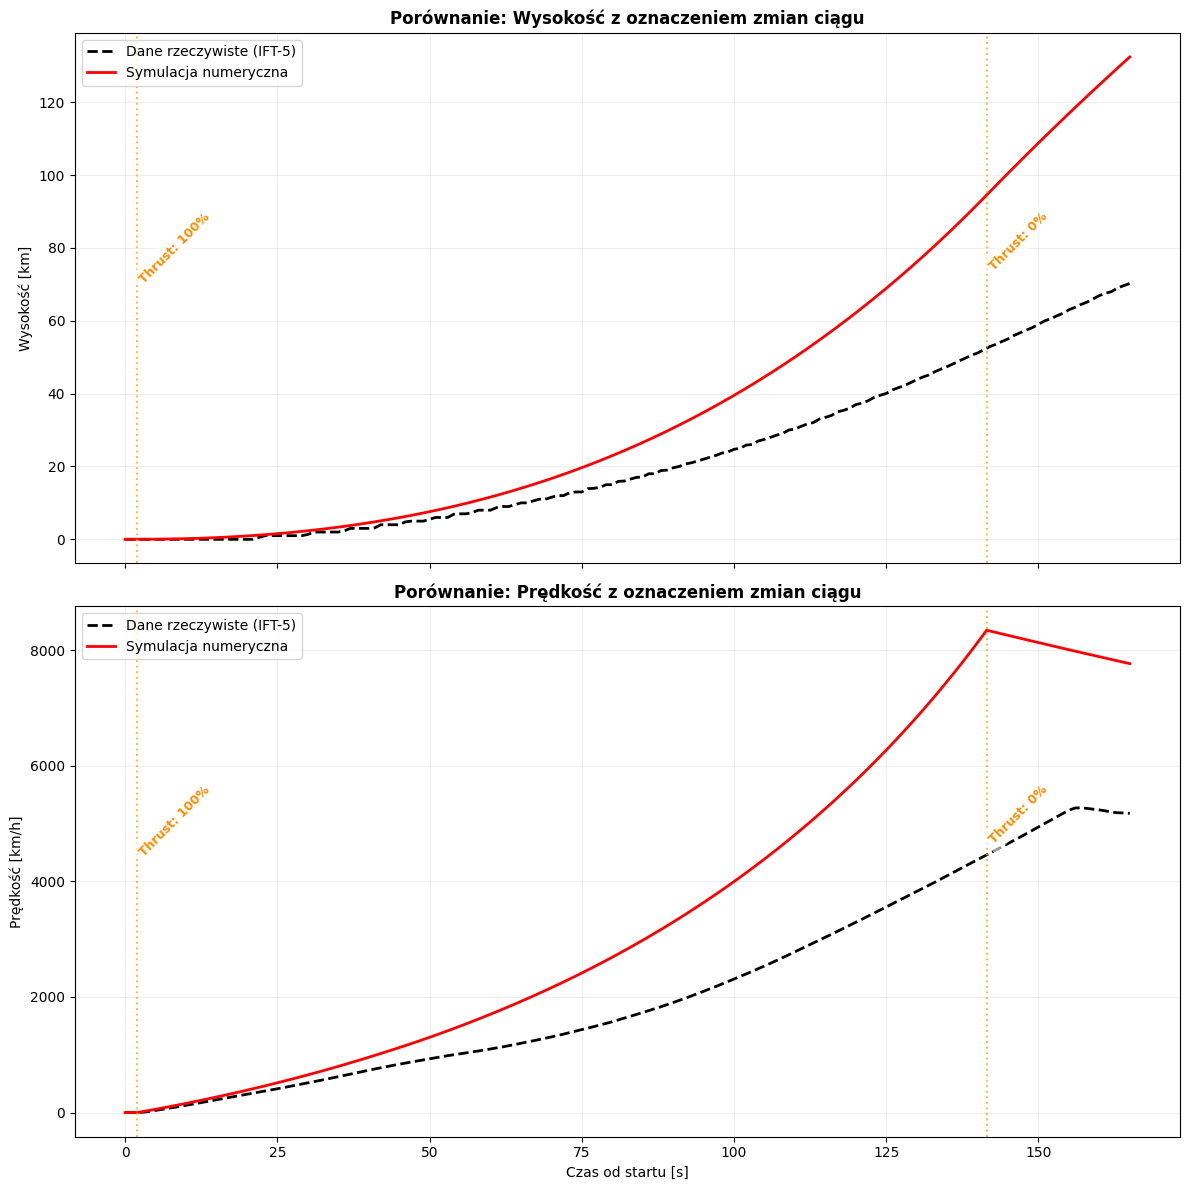

In [177]:
results_no_throttling = run_starship_simulation(guidance, enable_throttling=False)

plot_comparison_with_thrust(df_result, results_no_throttling)

### Wnioski z analizy scenariusza "Unrestricted Thrust" (Ciąg 100%)

Przeprowadzenie eksperymentu symulacyjnego przy założeniu stałego, maksymalnego ciągu silników (Throttle = 100%) ujawniło istotne rozbieżności względem danych telemetrycznych, które **potwierdzają poprawność fizyczną opracowanego modelu**:

1.  **Nadmiar energetyczny (Prędkość i Wysokość):**
    Symulowana rakieta osiągnęła znacznie wyższe parametry lotu (prędkość i pułap) niż rzeczywisty Booster w misji IFT-5. Jest to zachowanie oczekiwane i logiczne – model wykazuje, że bez celowego dławienia silników (*throttling*) rakieta dysponowałaby nadmiarem energii, co w rzeczywistości doprowadziłoby do przekroczenia dopuszczalnych obciążeń aerodynamicznych (Max-Q).

2.  **Bilans masy (Wyczerpanie paliwa):**
    Kluczowym obserwowanym zjawiskiem było wyczerpanie się zapasu materiałów pędnych przed planowanym czasem zakończenia symulacji (przed momentem separacji). Jest to zgodne z fizyką przepływu masowego:
    $$\frac{dm}{dt} \propto F_{thrust}$$
    Praca na 100% ciągu skutkuje maksymalnym zużyciem paliwa.

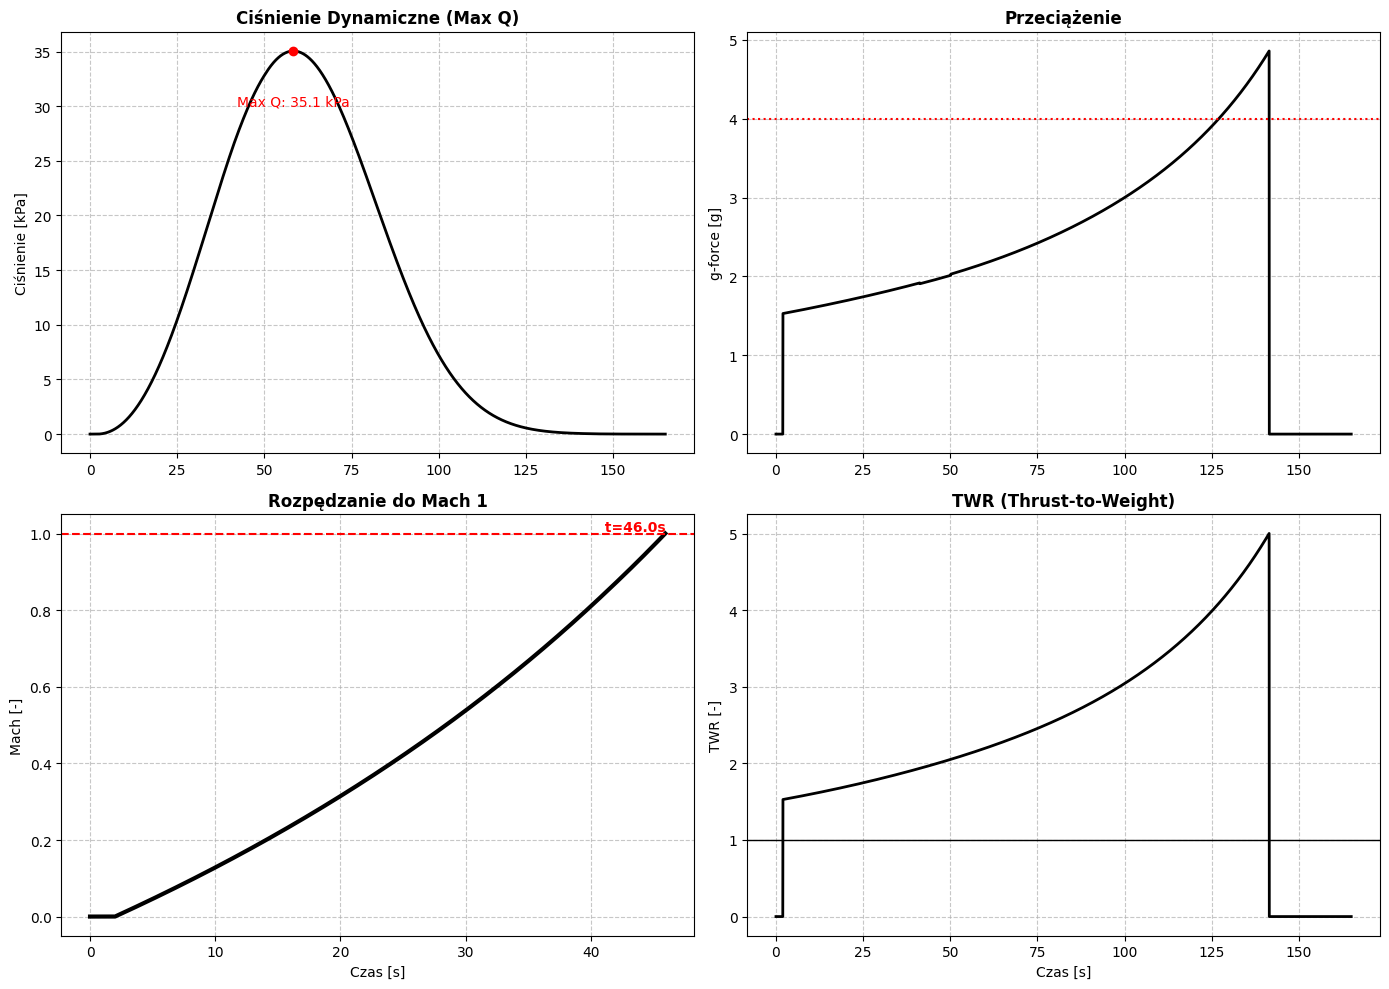

In [164]:
plot_engineering_panel(results_no_throttling)

### 6.1.2 Stała masa


🚀 START SYMULACJI (Solver: External RK4)


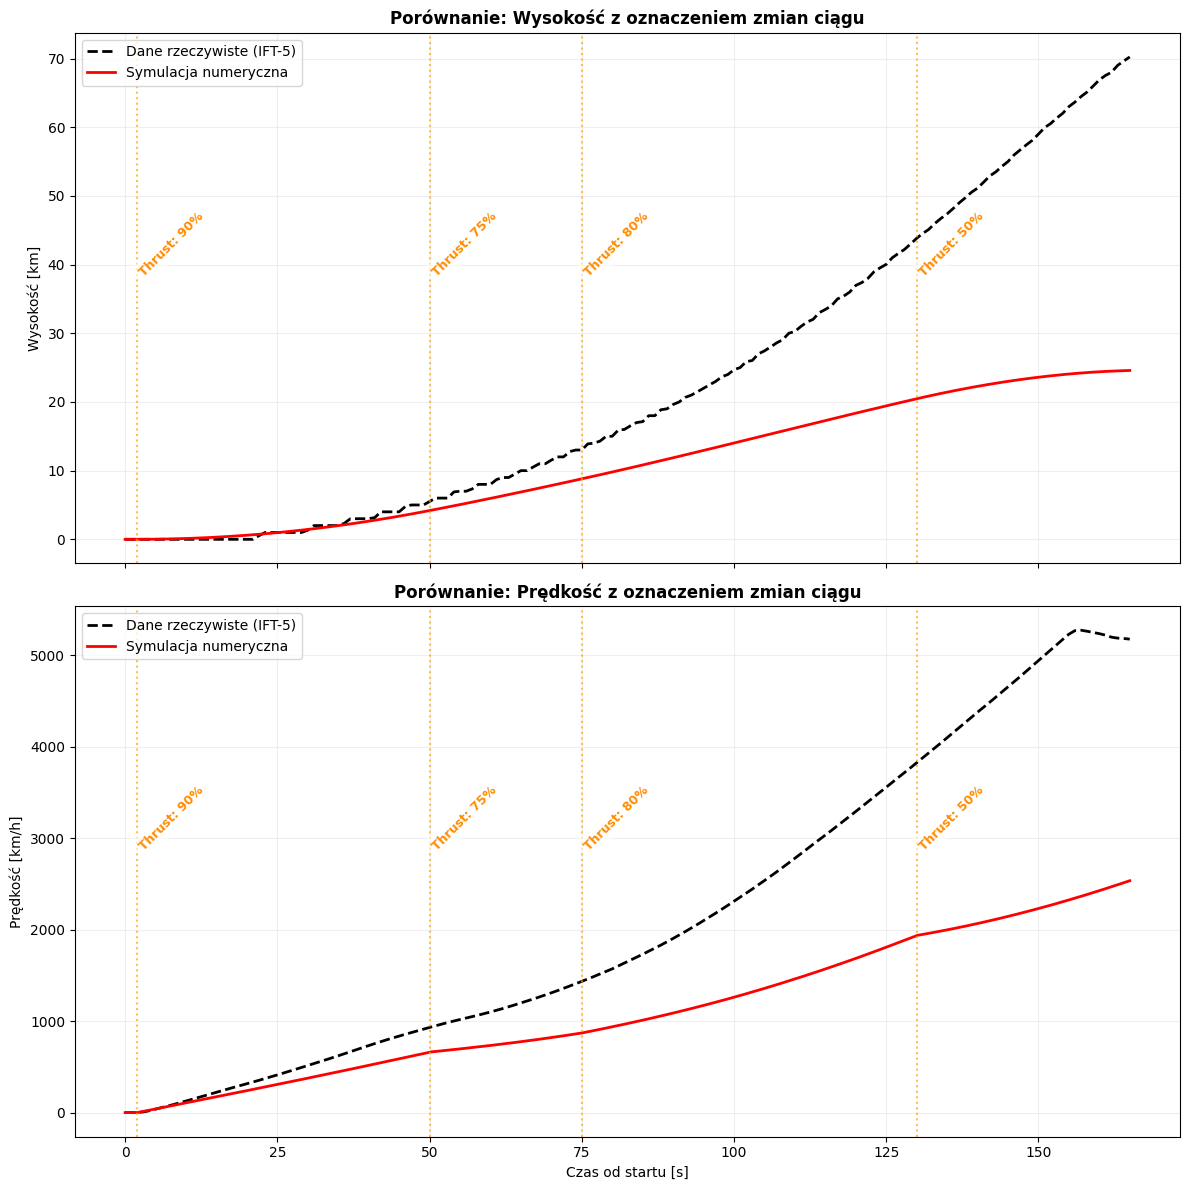

In [166]:
results_no_mass = run_starship_simulation(guidance, enable_mass_change=False)
plot_comparison_with_thrust(df_result, results_no_mass)

 Wyniki tego eksperymentu ukazują fundamentalną zasadę napędu rakietowego:

1.  **Brak przyrostu przyspieszenia:**
    W rzeczywistym locie przyspieszenie rakiety rośnie wykładniczo, ponieważ ciąg działa na coraz lżejszą konstrukcję ($a = F/m$). Przy założeniu stałej masy, przyspieszenie pozostaje niemal stałe i niskie (wynikające jedynie z początkowego TWR $\approx 1.5$).

2.  **Drastyczne niedoszacowanie prędkości:**
    Wykresy pokazują, że rakieta o stałej masie w 165s osiąga zaledwie ułamek prędkości rzeczywistego Boostera. Jest to dowód na to, że wysokie prędkości orbitalne osiąga się nie tyle dzięki "mocy" silników, co dzięki pozbywaniu się ogromnej masy zużytego paliwa.

**Wniosek:** Uwzględnienie pochodnej masy $\frac{dm}{dt}$ jest najważniejszym czynnikiem w modelowaniu dynamiki rakiety. Błąd wynikający z jej zaniedbania jest rzędu wielkości (kilkaset procent), podczas gdy błędy wynikające z aerodynamiki ($C_d$) to zazwyczaj kilka-kilkanaście procent.

### 7. Podsumowanie i wnioski końcowe

Celem niniejszego projektu było opracowanie i weryfikacja numerycznego modelu symulacyjnego pierwszego stopnia rakiety Starship (Super Heavy Booster) podczas testu w locie IFT-5. Analiza opierała się na rozwiązaniu układu równań różniczkowych ruchu z wykorzystaniem metody Rungego-Kutty 4. rzędu (RK4), przy użyciu danych wejściowych zrekonstruowanych na podstawie telemetryki wizualnej.

### Główne wnioski z analizy

1.  **Poprawność modelu fizycznego:**
    Uzyskana wysoka zbieżność wyników symulacji bazowej z danymi telemetrycznymi (szczególnie w zakresie profilu prędkości i momentu Max-Q) potwierdza, że przyjęte założenia fizyczne są poprawne. Model skutecznie odwzorowuje dynamikę lotu rakiety w atmosferze, uwzględniając zmienny opór aerodynamiczny oraz grawitacyjny.

2.  **Rekonstrukcja sterowania (Reverse Engineering):**
    Zastosowanie metody "inżynierii wstecznej" do odtworzenia profilu sterowania (*guidance*) na podstawie klatek kluczowych z transmisji wideo (zidentyfikowane kąty pochylenia: $77^\circ$ w $T+56s$ oraz $32^\circ$ w $T+159s$) okazało się kluczowe dla sukcesu symulacji. Liniowa aproksymacja zmian kąta natarcia pozwoliła na poprawne odwzorowanie manewru *Gravity Turn*.

3.  **Wnioski ze scenariuszy alternatywnych:**
    Przeprowadzona analiza wrażliwości dostarczyła istotnych dowodów na poprawność założeń modelu:
    * **Zarządzanie ciągiem:** Symulacja z ciągiem zablokowanym na 100% wykazała znaczne odchylenia od rzeczywistości (zbyt wysoka prędkość, przedwczesne zużycie paliwa), co stanowi dowód na stosowanie przez SpaceX głębokiego dławienia silników (*throttling*) w celu ograniczenia obciążeń dynamicznych i oszczędzania paliwa.


    * **Równanie Ciołkowskiego:** Eksperyment ze stałą masą (wyłączenie `dm/dt`) zobrazował fundamentalne znaczenie utraty masy paliwa dla uzyskania wymaganych przyspieszeń.

### Ograniczenia modelu i przyjęte idealizacje

Model numeryczny, mimo wysokiej zgodności z trajektorią główną, stanowi celową idealizację rzeczywistości. W procesie symulacji świadomie pominięto szereg złożonych zjawisk fizycznych oraz aspektów konstrukcyjnych, które mają wpływ na precyzję rzędu ułamków procenta, lecz wymagają znacznie bardziej zaawansowanych danych wejściowych:

* **Idealizacja środowiska atmosferycznego:**
    Model korzysta ze statycznego profilu atmosfery wzorcowej (ISA). W rzeczywistości na lot wpływają dynamiczne warunki pogodowe, takie jak **uskoki wiatru (wind shear)**, lokalne zmiany gęstości powietrza czy wilgotność, które modyfikują osiągi silników i aerodynamikę. Pominięto również wpływ **ruchu obrotowego Ziemi** (siła Coriolisa i siła odśrodkowa wynikająca z rotacji planety), traktując układ odniesienia jako inercjalny.

* **Uproszczona mechanika płynów i aerodynamika:**
    Symulacja redukuje całą złożoność opływu rakiety do jednego parametru ($C_d$). W rzeczywistości współczynnik ten zmienia się płynnie w funkcji liczby Macha, liczby Reynoldsa oraz kąta natarcia ($\alpha$). Model nie uwzględnia również **siły nośnej kadłuba** (body lift) generowanej przy dużych kątach natarcia, ani oporu generowanego przez elementy wystające, takie jak ruszty sterowe (Grid Fins).

* **Dynamika układu napędowego:**
    W kodzie założono natychmiastową reakcję silników na komendy sterujące. W rzeczywistości silniki rakietowe posiadają bezwładność (czas rozruchu i wygaszania turbopomp). Pominięto również zjawiska związane z **dynamiką paliwa w zbiornikach**, takie jak chlupotanie (*sloshing*) czy przemieszczanie się środka ciężkości (CoG) wzdłuż osi rakiety w miarę opróżniania zbiorników, co wpływa na stabilność lotu.

* **Brak aktywnego systemu sterowania (GNC):**
    Symulacja realizuje z góry założony scenariusz sterowania (tzw. *open-loop guidance*). Rzeczywista rakieta posiada zamkniętą pętlę sprzężenia zwrotnego (PID/MPC), która w czasie rzeczywistym koryguje drobne odchylenia trajektorii wynikające z turbulencji czy nierównej pracy silników.
### Konkluzja

Opracowany symulator stanowi skuteczne narzędzie do analizy mechaniki lotu dużych systemów nośnych. Mimo koniecznych uproszczeń, pozwala on na precyzyjne odtworzenie trajektorii lotu IFT-5 oraz zrozumienie decyzji inżynieryjnych podejmowanych podczas rzeczywistej misji, takich jak profilowanie ciągu czy sterowanie wektorem prędkości.

---
## Bibliografia
[1] https://web.archive.org/web/20090617153250/http://www.ar.krakow.pl/fizyka/cwicz10.pdf

[2] https://arxiv.org/pdf/1003.1508

[3] https://pl.wikipedia.org/wiki/Prawo_powszechnego_ci%C4%85%C5%BCenia

[4] https://www.grc.nasa.gov/www/k-12/airplane/atmosmet.html

[5] https://everydayastronaut.com/starship-super-heavy-flight-5/

[6] https://www.spacex.com/launches/starship-flight-5

[7]https://github.com/SofieBrink/StarshipTelemetryExtractor

[8] https://www.impan.pl/~szczep/AMM1/Kincaid.pdf

[9] https://pl.wikipedia.org/wiki/R%C3%B3wnanie_Mieszczerskiego

[10] https://www.spacex.com/vehicles/starship

[11] https://www.nasaspaceflight.com/